# Estudo dirigido: MLP com backpropagation na base Dry Bean

Experimento principal da **Avaliação RNA 2026.2**. O notebook executa as sete etapas do enunciado e
grava tabelas e figuras em `results/` e `report/tables/`. A análise completa de cada etapa está no
relatório (`report/relatorio.pdf`).

**Regras que valem para todo o notebook**

- **Modelo:** `MLPClassifier` treinado por SGD com momento clássico. ReLU nas camadas ocultas, softmax
  na saída e entropia cruzada categórica como perda. A classe já faz o one-hot dos rótulos internamente.
- **Dados:** divisão estratificada 70/15/15. O z-score é ajustado apenas no treino de cada execução.
- **Parada:** perda de treino ≤ 0,001 ou limite de épocas. Como quase nenhuma rede atinge esse valor,
  a velocidade também é medida pelas épocas até a perda de treino chegar a 0,20.
- **Seleção:** até a Questão 5 toda escolha usa a validação. O teste só é lido onde o enunciado pede
  (Q4, Q5 e Q6), e só a Q6 decide algo com ele.
- **Métrica principal:** Medida-F macro, porque as classes são desbalanceadas.
- **Tempo:** os treinos rodam em paralelo, o que torna seus tempos incomparáveis. As comparações usam uma
  cronometragem separada, em ms/época, com um treino por vez, uma thread e o mínimo de cinco repetições.

O primeiro treino leva alguns minutos. Depois disso, os resultados vêm do cache em `results/.cache`.

In [1]:
import warnings
from dataclasses import replace

import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, log_loss
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from drybean_mlp import plots
from drybean_mlp.data import (
    DATASET_PATH,
    SHAPE_FEATURES,
    SIZE_FEATURES,
    load_dry_bean,
    split_dataset,
)
from drybean_mlp.experiments import (
    AUXILIARY_LOSS,
    Trial,
    aggregate,
    cross_validate_mlp,
    drop_redundant,
    measure_epoch_time,
    pick_balanced,
    rank_features,
    run_trials,
    top_k,
)
from drybean_mlp.reporting import save_figure, save_table
from drybean_mlp.training import MLPConfig

plots.set_style()
pd.set_option("display.max_columns", None, "display.width", 160)

FIVE_SEEDS = (0, 1, 2, 3, 4)
THREE_SEEDS = (0, 1, 2)
TARGET_LOSS = 0.001


# Contagens de épocas e tempos não precisam de quatro casas no relatório.
COLUMN_DIGITS = {
    "ms/época": 1,
    "Tempo total (s)": 1,
    "Épocas": 0,
    "Épocas até 0,20": 1,
    "Épocas até 0,001": 0,
    "Época val. mín.": 0,
    "dp épocas": 0,
    "LR": 3,
    "Momento": 1,
}


def show(table, name, digits=4):
    saved = save_table(table, name, digits=digits, column_digits=COLUMN_DIGITS)
    display(saved.style.format(precision=digits).hide(axis="index"))

## Dados

In [2]:
raw_rows = len(pd.read_excel(DATASET_PATH))
X, y = load_dry_bean()
splits = split_dataset(X, y)
CLASSES = sorted(y.unique())

overview = pd.DataFrame(
    {
        "Etapa": ["Base original", "Sem duplicatas", "Treino", "Validação", "Teste"],
        "Exemplos": [raw_rows, len(X), len(splits.y_train), len(splits.y_val), len(splits.y_test)],
    }
)
show(overview, "dados_visao_geral")
print(f"{X.shape[1]} atributos, {y.nunique()} classes, {X.isna().sum().sum()} valores ausentes")

Etapa,Exemplos
Base original,13611
Sem duplicatas,13543
Treino,9479
Validação,2032
Teste,2032


16 atributos, 7 classes, 0 valores ausentes


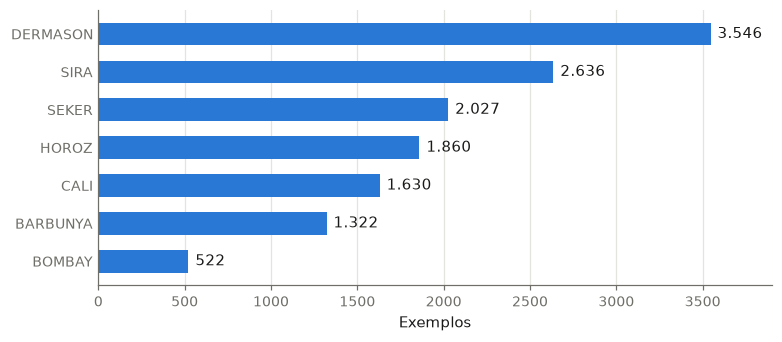

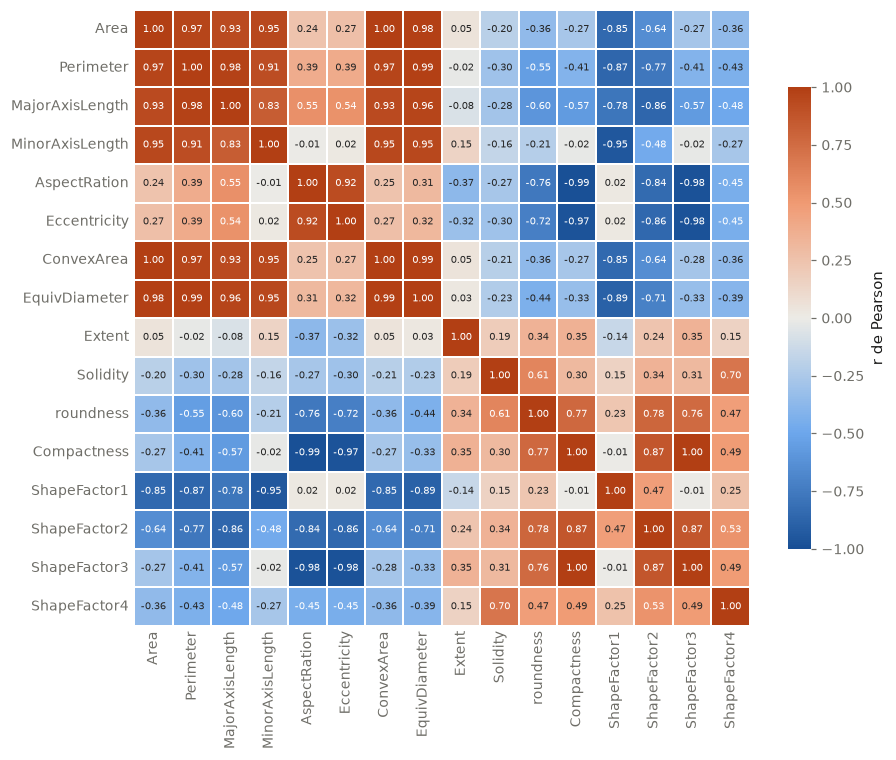

In [3]:
save_figure(plots.plot_class_counts(y), "dados_classes")
save_figure(plots.plot_correlation(X), "dados_correlacao");

## Questão 1: pesos iniciais e funções de ativação

**Configuração.** Duas camadas ocultas com 50 neurônios (dentro da faixa explorada na Q3), LR = 0,01,
momento = 0,9 e até 300 épocas. Cinco inicializações por função de ativação, usando **apenas o treino**.

In [4]:
Q1_CONFIG = MLPConfig(hidden_layers=(50, 50), learning_rate=0.01, momentum=0.9, max_epochs=300)

q1_trials = [
    Trial(activation, replace(Q1_CONFIG, activation=activation), seed)
    for activation in ("relu", "tanh", "logistic")
    for seed in FIVE_SEEDS
]
q1 = run_trials(q1_trials, splits, monitor=())

q1_relu = q1.summary[q1.summary["label"] == "relu"]
show(
    q1_relu[["seed", "train_loss", "train_accuracy", "train_f1", "epochs"]].rename(
        columns={
            "seed": "Seed",
            "train_loss": "Perda final",
            "train_accuracy": "Acurácia final",
            "train_f1": "Medida-F",
            "epochs": "Épocas",
        }
    ),
    "q1_seeds",
)

q1_agg = aggregate(q1.summary)
show(
    q1_agg[["label", "train_loss_mean", "train_loss_std", "train_accuracy_mean", "train_accuracy_std",
            "epochs_to_aux_mean"]].rename(
        columns={
            "label": "Ativação",
            "train_loss_mean": "Perda (média)",
            "train_loss_std": "Perda (dp)",
            "train_accuracy_mean": "Acurácia (média)",
            "train_accuracy_std": "Acurácia (dp)",
            "epochs_to_aux_mean": "Épocas até 0,20",
        }
    ),
    "q1_ativacoes",
)

Seed,Perda final,Acurácia final,Medida-F,Épocas
0,0.1476,0.9446,0.9550,300
1,0.1460,0.9458,0.9562,300
2,0.1502,0.9441,0.9545,300
3,0.1483,0.9446,0.9546,300
4,0.1479,0.9463,0.9564,300


Ativação,Perda (média),Perda (dp),Acurácia (média),Acurácia (dp),"Épocas até 0,20"
relu,0.1480,0.0015,0.9451,0.0009,11.8000
tanh,0.1520,0.0008,0.9434,0.0006,16.6000
logistic,0.1947,0.0016,0.9283,0.0007,238.8000


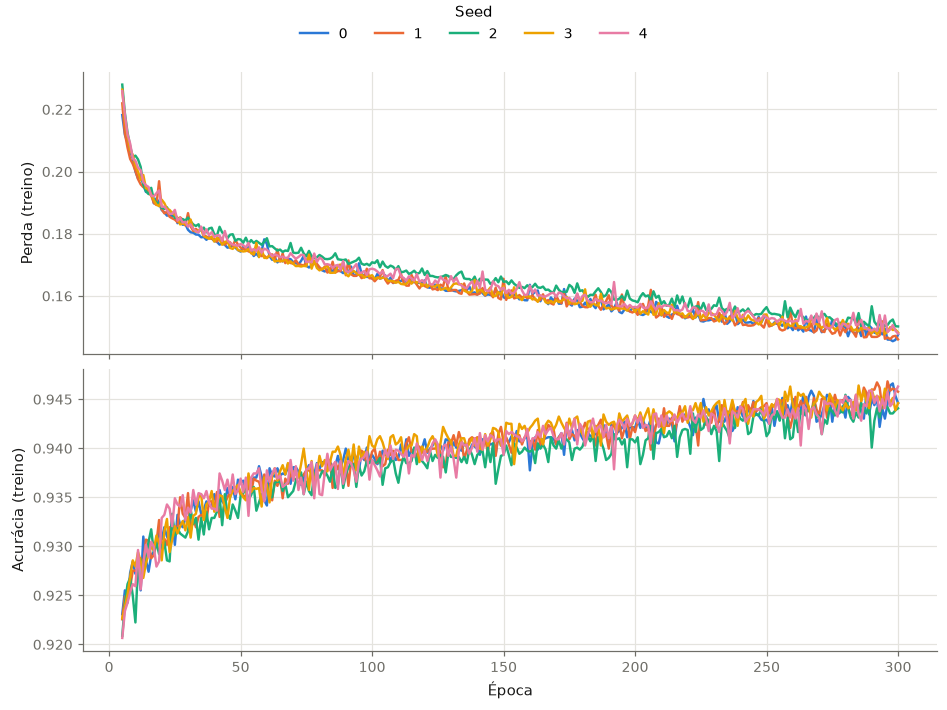

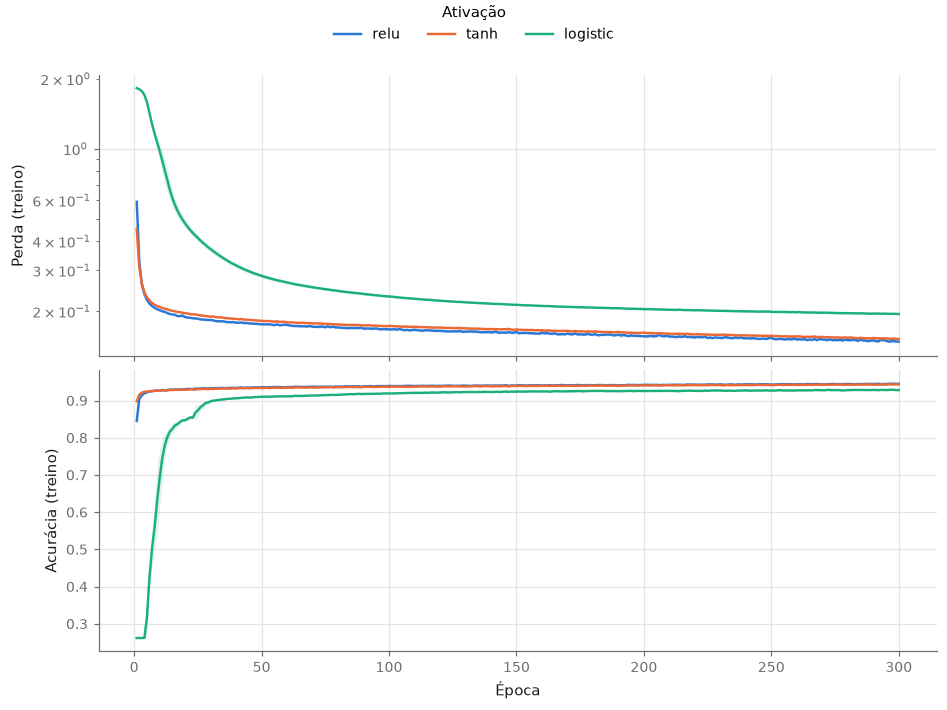

In [5]:
q1_relu_history = q1.histories[q1.histories["label"] == "relu"]
save_figure(plots.plot_curves(q1_relu_history, hue="seed", legend_title="Seed", min_epoch=5), "q1_curvas_seeds")
save_figure(plots.plot_curves(q1.histories, hue="label", legend_title="Ativação", log_y=("train_loss",)), "q1_curvas_ativacoes");

**Leitura.** Com ReLU, as cinco inicializações terminam em perda 0,148 ± 0,0015 e acurácia 0,945 ± 0,0009,
então a sensibilidade aos pesos iniciais é pequena. A tanh fica próxima (perda 0,152), e a logistic é bem mais
lenta: 239 épocas até a perda de 0,20, contra 12 da ReLU.

## Questão 2: taxa de aprendizado e termo momento

**Configuração.** Mesma topologia da Q1, grade LR × momento com três seeds e até 500 épocas, com
parada em perda ≤ 0,001. Os pesos são atualizados só com o treino; a validação apenas acompanha.

**Regra de escolha (definida antes de rodar a grade).** Entre as configurações sem divergência e com
perda final de validação até 5% acima da melhor, fica a mais rápida até a perda de treino de 0,20.

In [6]:
LEARNING_RATES = (0.001, 0.01, 0.1, 0.5)
MOMENTA = (0.5, 0.7, 0.9)

q2_trials = [
    Trial(
        f"LR={lr} m={momentum}",
        MLPConfig(hidden_layers=Q1_CONFIG.hidden_layers, learning_rate=lr, momentum=momentum,
                  max_epochs=500, target_loss=TARGET_LOSS),
        seed,
    )
    for lr in LEARNING_RATES
    for momentum in MOMENTA
    for seed in THREE_SEEDS
]
q2 = run_trials(q2_trials, splits, monitor=("val",))
q2_agg = aggregate(q2.summary)

show(
    q2_agg[["learning_rate", "momentum", "train_loss_mean", "train_loss_std", "val_loss_mean",
            "val_loss_min_mean", "val_f1_mean", "epochs_to_aux_mean", "epochs_to_target_mean",
            "runs_reached_target", "runs_diverged"]].rename(
        columns={
            "learning_rate": "LR",
            "momentum": "Momento",
            "train_loss_mean": "Perda treino",
            "train_loss_std": "dp treino",
            "val_loss_mean": "Perda val.",
            "val_loss_min_mean": "Perda val. mín.",
            "val_f1_mean": "F1 val.",
            "epochs_to_aux_mean": "Épocas até 0,20",
            "epochs_to_target_mean": "Épocas até 0,001",
            "runs_reached_target": "Atingiu 0,001",
            "runs_diverged": "Divergiu",
        }
    ),
    "q2_grade",
)

best_q2 = pick_balanced(q2_agg)
BEST_LR, BEST_MOMENTUM = float(best_q2["learning_rate"]), float(best_q2["momentum"])
print(f"Escolhidos: LR={BEST_LR}, momento={BEST_MOMENTUM}")
print(f"Perda val.={best_q2['val_loss_mean']:.4f}, épocas até {AUXILIARY_LOSS}={best_q2['epochs_to_aux_mean']:.0f}")

LR,Momento,Perda treino,dp treino,Perda val.,Perda val. mín.,F1 val.,"Épocas até 0,20","Épocas até 0,001","Atingiu 0,001",Divergiu
0.0010,0.5000,0.1977,0.0005,0.2130,0.2130,0.9317,447.3333,nan,0,0
0.0010,0.7000,0.1889,0.0002,0.2042,0.2042,0.9339,268.6667,nan,0,0
0.0010,0.9000,0.1745,0.0011,0.1950,0.1947,0.9352,90.6667,nan,0,0
0.0100,0.5000,0.1659,0.0012,0.1919,0.1916,0.9348,45.3333,nan,0,0
0.0100,0.7000,0.1584,0.0009,0.1908,0.1899,0.9348,28.0000,nan,0,0
0.0100,0.9000,0.1356,0.0022,0.2032,0.1875,0.9350,11.6667,nan,0,0
0.1000,0.5000,0.1143,0.0054,0.2406,0.1889,0.9313,6.3333,nan,0,0
0.1000,0.7000,0.0885,0.0005,0.3055,0.1883,0.9269,5.6667,nan,0,0
0.1000,0.9000,0.0735,0.0265,0.5709,0.1910,0.9244,4.0000,nan,0,0
0.5000,0.5000,0.0502,0.0002,0.5351,0.1927,0.9249,4.6667,nan,0,0


Escolhidos: LR=0.01, momento=0.7
Perda val.=0.1908, épocas até 0.2=28


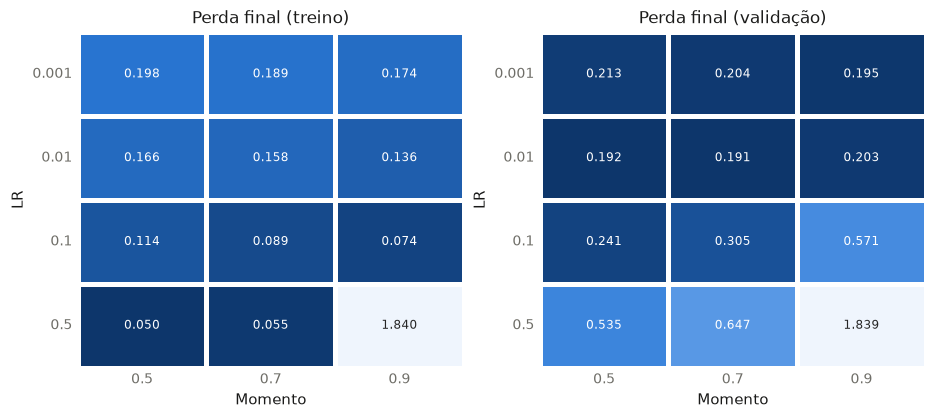

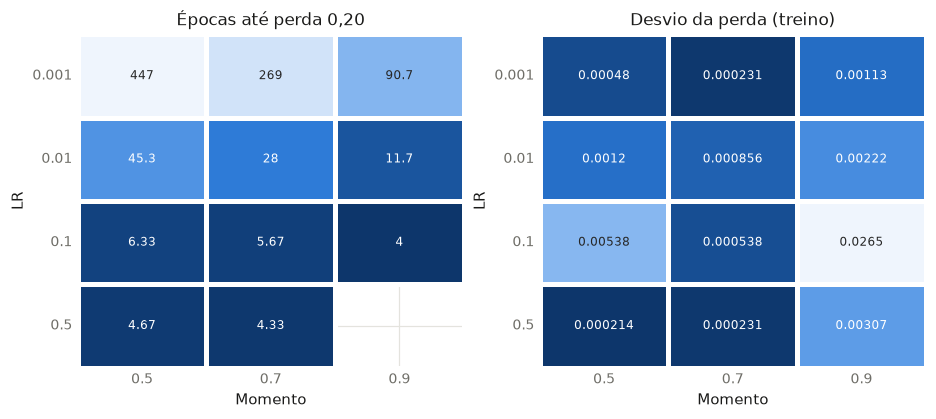

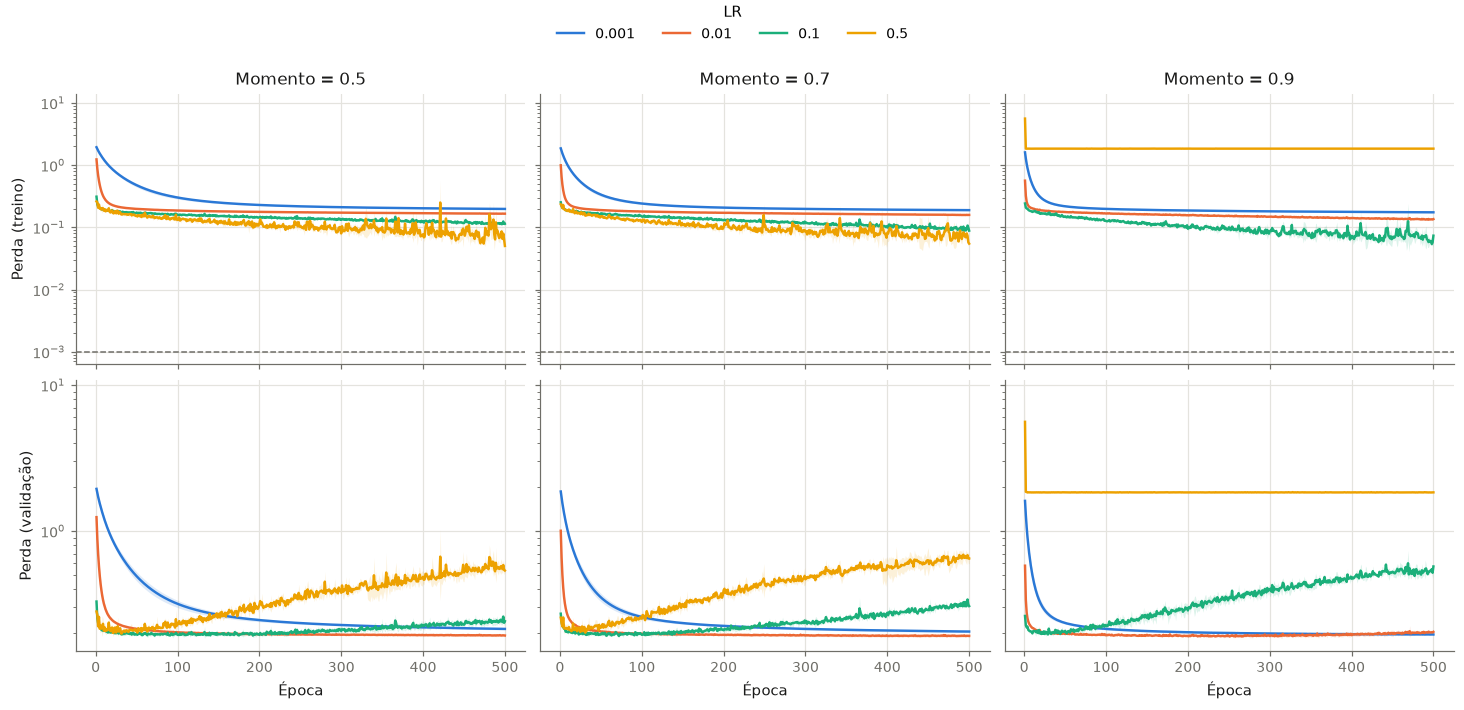

In [7]:
def q2_pivot(column):
    return q2_agg.pivot(index="learning_rate", columns="momentum", values=column).rename_axis(
        index="LR", columns="Momento"
    )


save_figure(
    plots.plot_heatmaps(
        {
            "Perda final (treino)": q2_pivot("train_loss_mean"),
            "Perda final (validação)": q2_pivot("val_loss_mean"),
        },
        reverse=("Perda final (treino)", "Perda final (validação)"),
        log_color=("Perda final (treino)", "Perda final (validação)"),
    ),
    "q2_heatmap_perdas",
)
save_figure(
    plots.plot_heatmaps(
        {
            "Épocas até perda 0,20": q2_pivot("epochs_to_aux_mean"),
            "Desvio da perda (treino)": q2_pivot("train_loss_std"),
        },
        fmt=".3g",
        reverse=("Épocas até perda 0,20", "Desvio da perda (treino)"),
        log_color=("Épocas até perda 0,20", "Desvio da perda (treino)"),
    ),
    "q2_heatmap_velocidade",
)

q2_history = q2.histories.merge(
    q2.summary[["label", "seed", "learning_rate", "momentum"]].rename(
        columns={"momentum": "Momento", "learning_rate": "LR"}
    ),
    on=["label", "seed"],
)
save_figure(
    plots.plot_curves(
        q2_history, hue="LR", hue_order=LEARNING_RATES, facet="Momento", facet_order=MOMENTA,
        metrics=("train_loss", "val_loss"), log_y=("train_loss", "val_loss"),
        reference_lines={"train_loss": TARGET_LOSS}, legend_title="LR",
    ),
    "q2_curvas",
);

### Convergência até a perda de 0,001

A grade acima usa 500 épocas, e nenhuma combinação chega a 0,001 nesse limite. Para medir a velocidade de convergência como o
enunciado a define (épocas até a perda de treino ≤ 0,001), a mesma grade roda de novo com limite de 5.000 épocas e para assim
que atinge 0,001. A escolha de LR e momento continua sendo a da grade de 500 épocas: com 5.000 épocas, a perda final de
validação passaria a medir sobretudo o overfitting acumulado.

LR,Momento,"Atingiu 0,001","Épocas até 0,001",dp épocas,Perda treino,Acur. treino,Perda val.,Perda val. mín.,F1 val.
0.0010,0.5000,0,nan,nan,0.1655,0.9393,0.1925,0.1925,0.9354
0.0010,0.7000,0,nan,nan,0.1574,0.9419,0.1908,0.1906,0.9345
0.0010,0.9000,0,nan,nan,0.1295,0.9520,0.2006,0.1890,0.9364
0.0100,0.5000,0,nan,nan,0.0992,0.9641,0.2560,0.1886,0.9316
0.0100,0.7000,0,nan,nan,0.0747,0.9728,0.3586,0.1892,0.9286
0.0100,0.9000,0,nan,nan,0.0203,0.9937,0.8881,0.1875,0.9209
0.1000,0.5000,0,nan,nan,0.0028,0.9994,1.2579,0.1889,0.9210
0.1000,0.7000,3,4136.3333,730.3810,0.0010,1.0000,1.3881,0.1883,0.9198
0.1000,0.9000,3,2443.3333,274.5038,0.0009,1.0000,1.5259,0.1910,0.9180
0.5000,0.5000,1,2861.0000,nan,1.1109,0.5446,1.6303,0.1927,0.3900


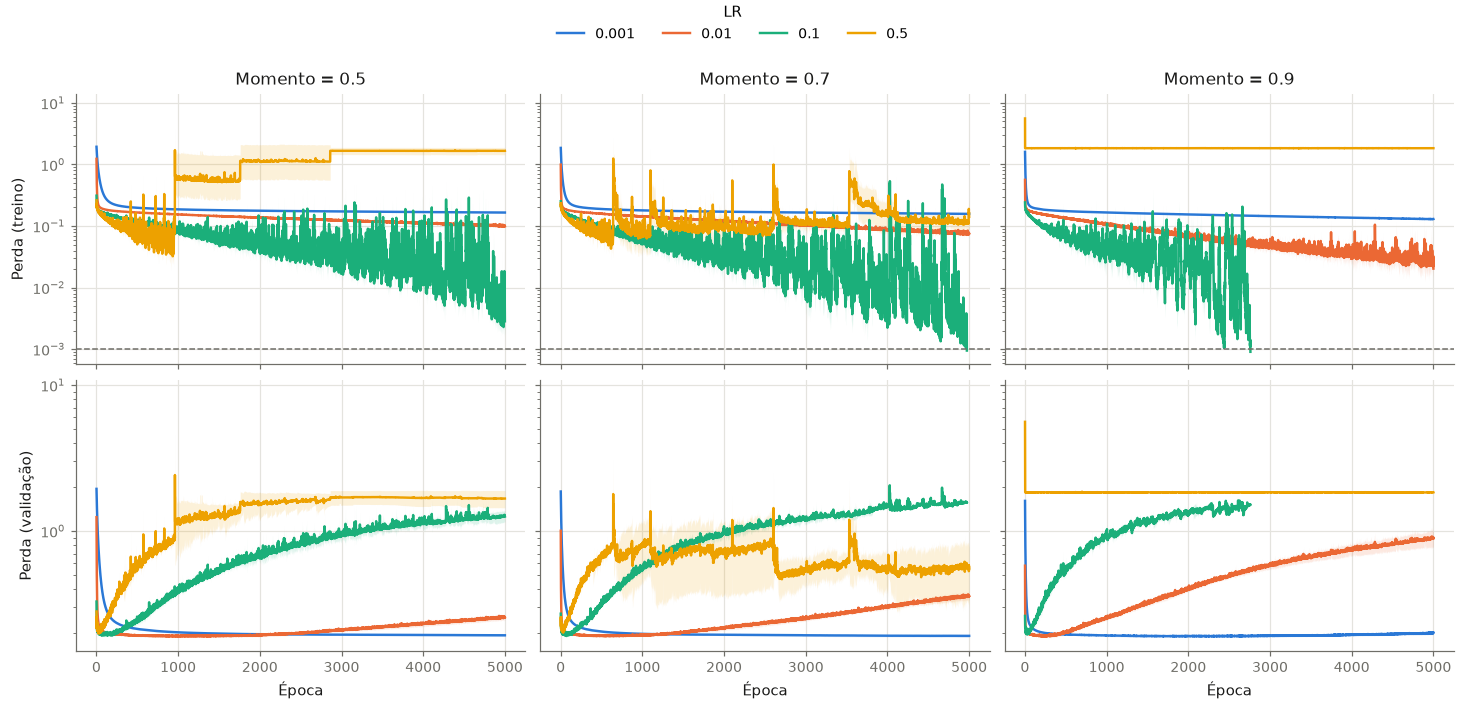

In [8]:
LONG_EPOCHS = 5000

q2_long = run_trials(
    [
        Trial(
            f"LR={lr} m={momentum}",
            MLPConfig(hidden_layers=Q1_CONFIG.hidden_layers, learning_rate=lr, momentum=momentum,
                      max_epochs=LONG_EPOCHS, target_loss=TARGET_LOSS),
            seed,
        )
        for lr in LEARNING_RATES
        for momentum in MOMENTA
        for seed in THREE_SEEDS
    ],
    splits,
    monitor=("val",),
)
q2_long_agg = aggregate(q2_long.summary)
show(
    q2_long_agg[["learning_rate", "momentum", "runs_reached_target", "epochs_to_target_mean", "epochs_to_target_std",
                 "train_loss_mean", "train_accuracy_mean", "val_loss_mean", "val_loss_min_mean", "val_f1_mean"]].rename(
        columns={
            "learning_rate": "LR",
            "momentum": "Momento",
            "runs_reached_target": "Atingiu 0,001",
            "epochs_to_target_mean": "Épocas até 0,001",
            "epochs_to_target_std": "dp épocas",
            "train_loss_mean": "Perda treino",
            "train_accuracy_mean": "Acur. treino",
            "val_loss_mean": "Perda val.",
            "val_loss_min_mean": "Perda val. mín.",
            "val_f1_mean": "F1 val.",
        }
    ),
    "q2_convergencia",
)

q2_long_history = q2_long.histories.merge(
    q2_long.summary[["label", "seed", "learning_rate", "momentum"]].rename(
        columns={"momentum": "Momento", "learning_rate": "LR"}
    ),
    on=["label", "seed"],
)
save_figure(
    plots.plot_curves(
        q2_long_history, hue="LR", hue_order=LEARNING_RATES, facet="Momento", facet_order=MOMENTA,
        metrics=("train_loss", "val_loss"), log_y=("train_loss", "val_loss"),
        reference_lines={"train_loss": TARGET_LOSS}, legend_title="LR",
    ),
    "q2_convergencia",
);

### Verificação: efeito de `warm_start` em comparação com `partial_fit`

A documentação do scikit-learn sugere `warm_start=True` com `max_iter=1` para monitorar o treino, mas
`fit` recria o otimizador a cada chamada, o que zera a velocidade do momento a cada época. Além disso, uma
seed inteira repete o embaralhamento em todas as épocas. Este experimento mede o tamanho real desses
efeitos, com a mesma métrica (`log_loss` no treino ao fim da época) e três seeds.

Configuração,Laço,Perda na época 200,dp
"LR=0,01 m=0,9",partial_fit,0.1566,0.0016
"LR=0,01 m=0,9",warm_start,0.1600,0.0017
"LR=0,01 m=0,9","warm_start, seed inteira",0.1613,0.0031
"LR=0,1 m=0,9",partial_fit,0.0949,0.0057
"LR=0,1 m=0,9",warm_start,0.1066,0.0007
"LR=0,1 m=0,9","warm_start, seed inteira",0.1190,0.0111


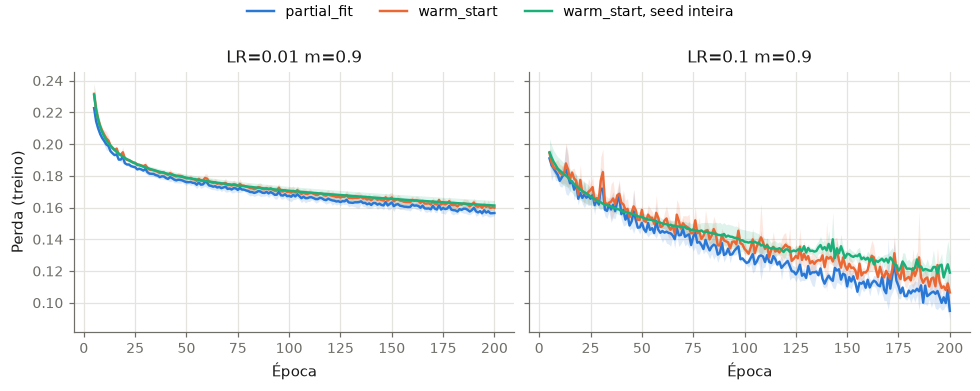

In [9]:
def warm_start_history(X_scaled, y_train, lr, momentum, epochs, seed, integer_seed):
    model = MLPClassifier(
        hidden_layer_sizes=Q1_CONFIG.hidden_layers, solver="sgd", learning_rate_init=lr,
        momentum=momentum, nesterovs_momentum=False, batch_size=200, max_iter=1, warm_start=True,
        random_state=seed if integer_seed else np.random.RandomState(seed),
    )
    losses = []
    with warnings.catch_warnings():
        # Com max_iter=1 todo fit avisa que não convergiu: é esperado neste laço, e só neste.
        warnings.simplefilter("ignore", ConvergenceWarning)
        for _ in range(epochs):
            model.fit(X_scaled, y_train)
            losses.append(log_loss(y_train, model.predict_proba(X_scaled), labels=model.classes_))
    loop = "warm_start, seed inteira" if integer_seed else "warm_start"
    return pd.DataFrame(
        {"epoch": range(1, epochs + 1), "train_loss": losses, "seed": seed, "Laço": loop,
         "Configuração": f"LR={lr} m={momentum}"}
    )


LOOP_EPOCHS = 200
LOOP_CONFIGS = ((0.01, 0.9), (0.1, 0.9))
X_scaled = StandardScaler().fit_transform(splits.X_train)
warm_histories = Parallel(n_jobs=-1)(
    delayed(warm_start_history)(X_scaled, splits.y_train, lr, momentum, LOOP_EPOCHS, seed, integer_seed)
    for lr, momentum in LOOP_CONFIGS for seed in THREE_SEEDS for integer_seed in (False, True)
)
partial_histories = [
    q2.histories.loc[
        (q2.histories["label"] == f"LR={lr} m={momentum}") & (q2.histories["epoch"] <= LOOP_EPOCHS),
        ["epoch", "train_loss", "seed"],
    ].assign(**{"Laço": "partial_fit", "Configuração": f"LR={lr} m={momentum}"})
    for lr, momentum in LOOP_CONFIGS
]
loops = pd.concat([*partial_histories, *warm_histories], ignore_index=True)

final_losses = loops[loops["epoch"] == LOOP_EPOCHS]
show(
    final_losses.groupby(["Configuração", "Laço"], as_index=False)["train_loss"].agg(["mean", "std"]).rename(
        columns={"mean": f"Perda na época {LOOP_EPOCHS}", "std": "dp"}
    ).assign(Configuração=lambda t: t["Configuração"].str.replace(".", ",")),
    "q2_laco_treino",
)
save_figure(
    plots.plot_curves(
        loops[loops["epoch"] >= 5], hue="Laço", hue_order=["partial_fit", "warm_start", "warm_start, seed inteira"],
        facet="Configuração", metrics=("train_loss",),
    ),
    "q2_laco_treino",
);

**Leitura.** A escolha foi LR = 0,01 e momento = 0,7. Nenhuma combinação atingiu perda ≤ 0,001 em 500 épocas.
Com LR = 0,5 e momento = 0,9 a rede colapsa: a perda fica em 1,84, a entropia das classes (1,8338), e a Medida-F em
0,0593, o valor de quem prevê só a classe majoritária. Os pesos continuam finitos, logo não é divergência numérica.
Os laços com `warm_start` terminam com perda maior (0,1600 contra 0,1566 com LR = 0,01; 0,1066 contra 0,0949 com
LR = 0,1): o efeito é real, porém moderado.

## Questão 3: número de camadas e de neurônios

**Configuração.** LR e momento da Q2, de 1 a 3 camadas ocultas iguais e de 10 a 100 neurônios por camada
(30 topologias), três seeds e até 500 épocas. O teste não é usado.

**Regra das quatro melhores (definida antes de rodar).** Maior valor de média − desvio da Medida-F na
validação, o que pontua desempenho e estabilidade ao mesmo tempo.

In [10]:
LAYER_COUNTS = (1, 2, 3)
WIDTHS = tuple(range(10, 101, 10))


def topology_config(layers, **overrides):
    defaults = dict(hidden_layers=layers, learning_rate=BEST_LR, momentum=BEST_MOMENTUM,
                    max_epochs=500, target_loss=TARGET_LOSS)
    return MLPConfig(**(defaults | overrides))


q3_trials = [
    Trial("×".join([str(width)] * depth), topology_config((width,) * depth), seed)
    for depth in LAYER_COUNTS
    for width in WIDTHS
    for seed in THREE_SEEDS
]
q3 = run_trials(q3_trials, splits, monitor=("val",))
q3_agg = aggregate(q3.summary)
q3_agg["depth"] = q3_agg["label"].str.count("×") + 1
q3_agg["width"] = q3_agg["label"].str.split("×").str[0].astype(int)
q3_agg["gap"] = q3_agg["val_loss_mean"] - q3_agg["train_loss_mean"]

q3_timing = measure_epoch_time([trial for trial in q3_trials if trial.seed == 0], splits)
q3_agg = q3_agg.merge(q3_timing[["label", "ms_per_epoch"]], on="label")
q3_agg["total_seconds"] = q3_agg["ms_per_epoch"] * q3_agg["epochs_mean"] / 1000


def q3_view(table):
    return table[["label", "train_loss_mean", "val_loss_mean", "gap", "val_accuracy_mean", "val_f1_mean",
                  "val_f1_std", "val_precision_mean", "val_recall_mean", "val_loss_min_epoch_mean",
                  "epochs_mean", "ms_per_epoch", "total_seconds"]].rename(
        columns={
            "label": "Topologia",
            "train_loss_mean": "Perda treino",
            "val_loss_mean": "Perda val.",
            "gap": "Diferença",
            "val_accuracy_mean": "Acurácia val.",
            "val_f1_mean": "F1 val.",
            "val_f1_std": "dp F1",
            "val_precision_mean": "Precisão",
            "val_recall_mean": "Revocação",
            "val_loss_min_epoch_mean": "Época val. mín.",
            "epochs_mean": "Épocas",
            "ms_per_epoch": "ms/época",
            "total_seconds": "Tempo total (s)",
        }
    )


show(q3_view(q3_agg).drop(columns=["Precisão", "Revocação", "Épocas"]), "q3_topologias")

q3_top4 = top_k(q3_agg, k=4)
show(q3_view(q3_top4), "q3_top4")
TOP_TOPOLOGIES = [tuple(int(n) for n in label.split("×")) for label in q3_top4["label"]]
BEST_TOPOLOGY = TOP_TOPOLOGIES[0]
print("Quatro melhores:", list(q3_top4["label"]), "| melhor:", BEST_TOPOLOGY)

Topologia,Perda treino,Perda val.,Diferença,Acurácia val.,F1 val.,dp F1,Época val. mín.,ms/época,Tempo total (s)
10,0.1835,0.2088,0.0253,0.9229,0.9322,0.0008,489.0000,15.7623,7.8811
20,0.1791,0.2003,0.0212,0.9268,0.9357,0.0035,476.6667,15.9903,7.9951
30,0.1756,0.1966,0.0210,0.9252,0.9350,0.0027,493.6667,16.9808,8.4904
40,0.1739,0.1972,0.0233,0.9260,0.9357,0.0010,499.6667,18.2400,9.1200
50,0.1743,0.1956,0.0213,0.9268,0.9363,0.0004,498.0000,18.6829,9.3415
60,0.1728,0.1929,0.0201,0.9265,0.9362,0.0006,498.0000,20.1731,10.0865
70,0.1727,0.1941,0.0213,0.9278,0.9371,0.0010,498.0000,21.1491,10.5746
80,0.1720,0.1925,0.0205,0.9262,0.9358,0.0016,498.0000,21.8979,10.9490
90,0.1717,0.1946,0.0228,0.9270,0.9371,0.0017,490.0000,22.6346,11.3173
100,0.1711,0.1952,0.0241,0.9254,0.9353,0.0006,486.0000,22.7305,11.3653


Topologia,Perda treino,Perda val.,Diferença,Acurácia val.,F1 val.,dp F1,Precisão,Revocação,Época val. mín.,Épocas,ms/época,Tempo total (s)
80×80,0.1539,0.1882,0.0342,0.9265,0.9380,0.0006,0.9383,0.9380,497.6667,500.0000,34.2323,17.1161
90×90,0.1535,0.1853,0.0318,0.9260,0.9373,0.0008,0.9376,0.9374,488.6667,500.0000,38.7771,19.3886
80×80×80,0.1436,0.1981,0.0545,0.9252,0.9376,0.0013,0.9378,0.9382,268.6667,500.0000,45.7833,22.8917
60×60×60,0.1435,0.1958,0.0523,0.9245,0.9363,0.0002,0.9365,0.9365,304.3333,500.0000,36.9330,18.4665


Quatro melhores: ['80×80', '90×90', '80×80×80', '60×60×60'] | melhor: (80, 80)


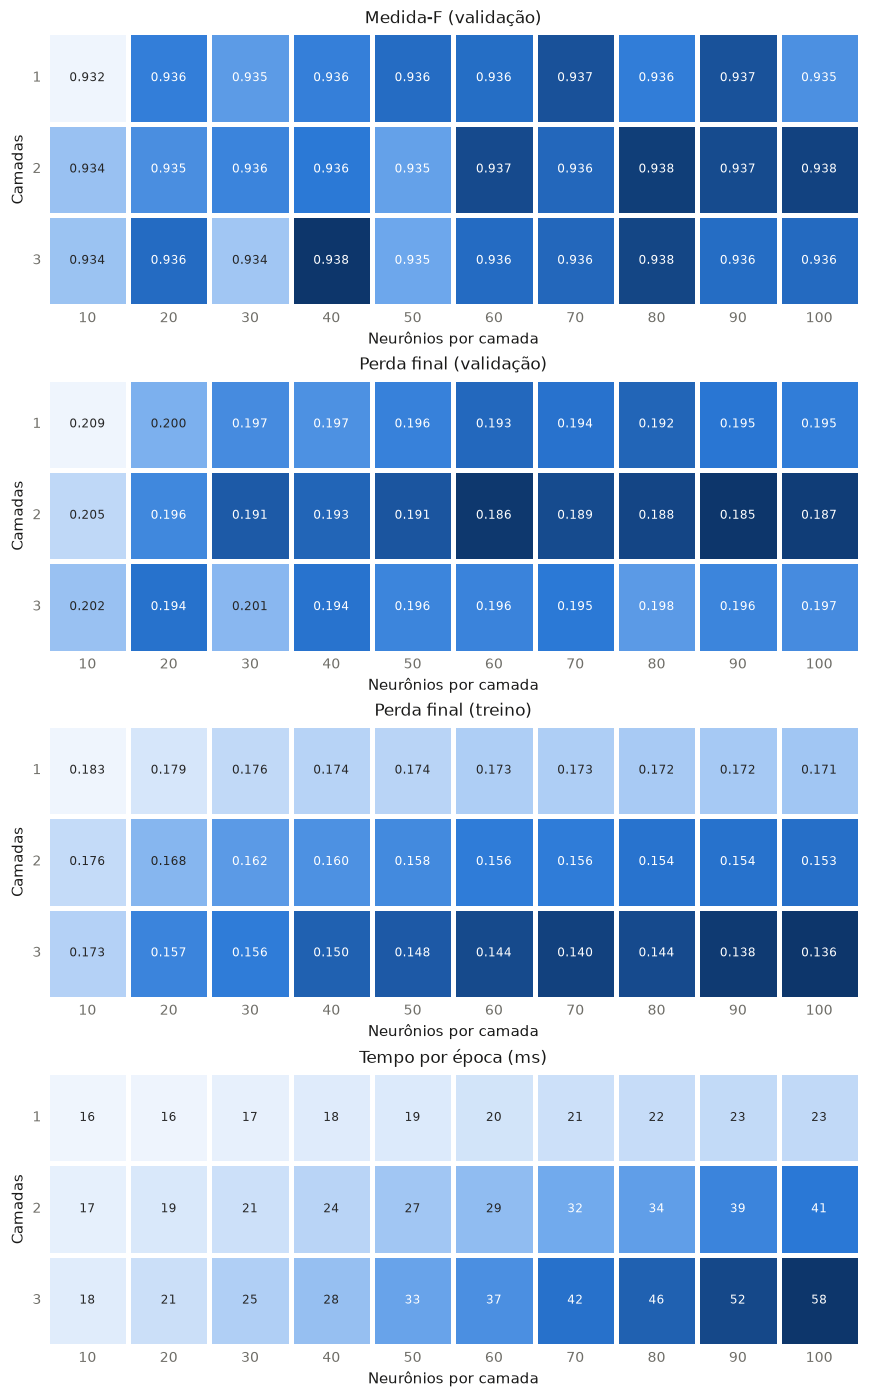

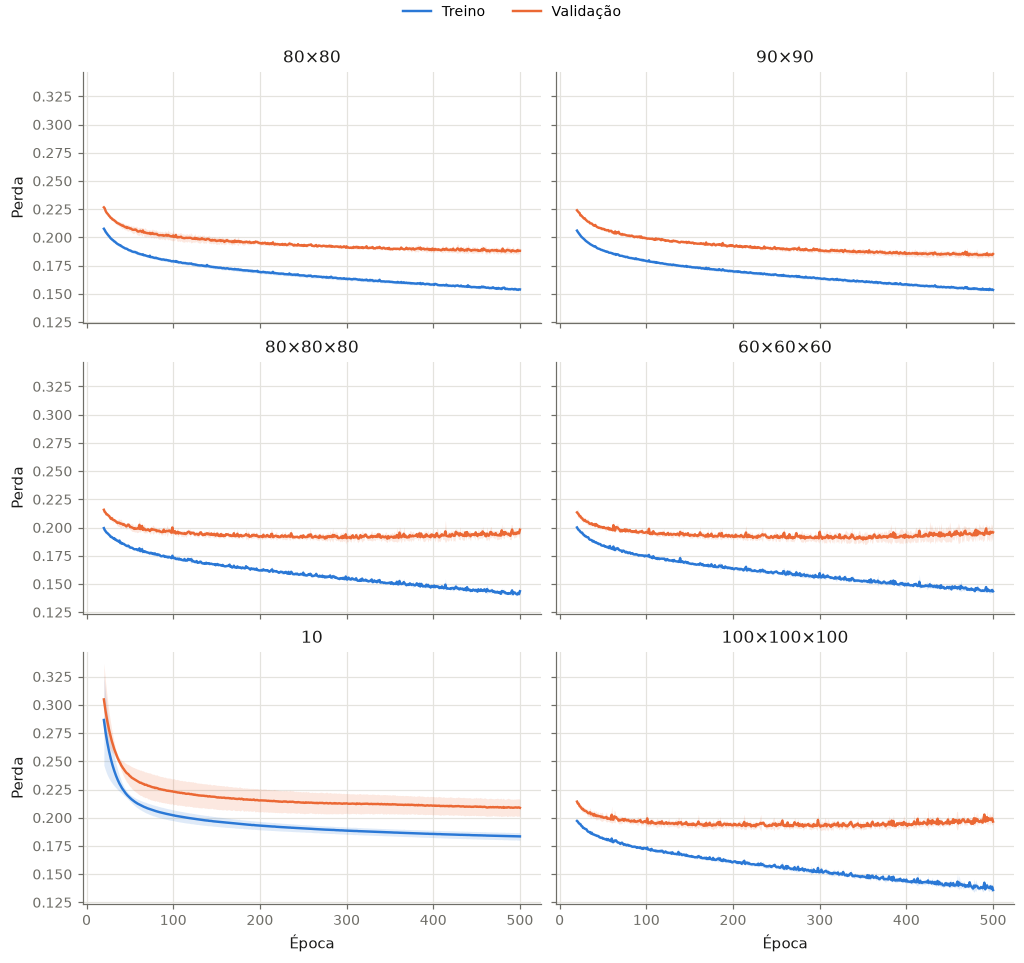

In [11]:
def q3_pivot(column):
    return q3_agg.pivot(index="depth", columns="width", values=column).rename_axis(
        index="Camadas", columns="Neurônios por camada"
    )


save_figure(
    plots.plot_heatmaps(
        {
            "Medida-F (validação)": q3_pivot("val_f1_mean"),
            "Perda final (validação)": q3_pivot("val_loss_mean"),
            "Perda final (treino)": q3_pivot("train_loss_mean"),
            "Tempo por época (ms)": q3_pivot("ms_per_epoch"),
        },
        fmt={"Medida-F (validação)": ".3f", "Perda final (validação)": ".3f",
             "Perda final (treino)": ".3f", "Tempo por época (ms)": ".0f"},
        reverse=("Perda final (validação)", "Perda final (treino)"),
        ncols=1,
    ),
    "q3_heatmaps",
)

extremes = ["10", "100×100×100"]
save_figure(
    plots.plot_train_vs_eval(q3.histories, list(q3_top4["label"]) + extremes, min_epoch=20),
    "q3_curvas",
);

### Contraste: a mesma família de redes com LR e momento altos

Com LR = 0,01 a grade acima varia pouco. Este caso, fora da grade e fora da seleção, mostra o que a
mesma topologia grande faz com LR = 0,1 e momento = 0,9: é onde o critério de perda ≤ 0,001 pode ser atingido.

Seed,Épocas,"Atingiu 0,001",Perda treino,Acur. treino,Perda val.,Acur. val.,F1 val.,Perda val. mín.,Época val. mín.
0,363,Sim,0.0009,0.9999,0.7966,0.9134,0.9278,0.1937,24
1,394,Sim,0.0008,0.9999,0.8289,0.9124,0.9265,0.1940,32
2,389,Sim,0.0009,1.0000,0.8243,0.9129,0.9243,0.1953,25


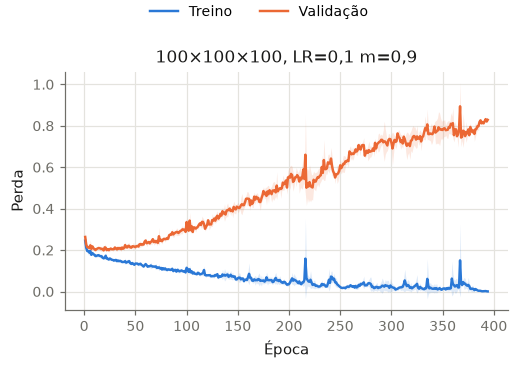

In [12]:
q3_contrast = run_trials(
    [Trial("100×100×100, LR=0,1 m=0,9", topology_config((100, 100, 100), learning_rate=0.1, momentum=0.9), seed)
     for seed in THREE_SEEDS],
    splits,
    monitor=("val",),
)
show(
    q3_contrast.summary[["seed", "epochs", "reached_target", "train_loss", "train_accuracy", "val_loss",
                         "val_accuracy", "val_f1", "val_loss_min", "val_loss_min_epoch"]].assign(
        reached_target=lambda t: t["reached_target"].map({True: "Sim", False: "Não"})
    ).rename(
        columns={
            "seed": "Seed",
            "epochs": "Épocas",
            "reached_target": "Atingiu 0,001",
            "train_loss": "Perda treino",
            "train_accuracy": "Acur. treino",
            "val_loss": "Perda val.",
            "val_accuracy": "Acur. val.",
            "val_f1": "F1 val.",
            "val_loss_min": "Perda val. mín.",
            "val_loss_min_epoch": "Época val. mín.",
        }
    ),
    "q3_contraste",
)
save_figure(
    plots.plot_train_vs_eval(q3_contrast.histories, ["100×100×100, LR=0,1 m=0,9"], ncols=1),
    "q3_contraste",
);

**Leitura.** A topologia muda pouco o resultado: a Medida-F média fica entre 0,932 e 0,938 nas 30 redes. A diferença
entre perda de validação e de treino cresce com a capacidade (de 0,02 a 0,06), e a de 3 camadas atinge o mínimo de
validação mais cedo. No contraste, as três seeds atingem o critério de 0,001 (acurácia de treino ≥ 0,9999), com a perda
de validação subindo de cerca de 0,19 para cerca de 0,80: é o overfitting que a grade com LR = 0,01 não mostra.

## Questão 4: quantidade e qualidade dos dados de treino

**Configuração.** Melhor rede da Q3, cinco seeds. Validação e teste permanecem fixos em todas as
condições, para que os números sejam comparáveis.

- **Quantidade:** frações de 5% a 100% do treino, com amostragem estratificada.
- **Qualidade (rótulos):** 5%, 10% e 20% dos rótulos de treino trocados por outra classe.
- **Qualidade (representatividade):** amostragem estratificada × aleatória em frações pequenas.

In [13]:
FRACTIONS = (0.05, 0.10, 0.20, 0.40, 0.60, 0.80, 1.00)
LABEL_NOISE = (0.05, 0.10, 0.20)
SAMPLING_FRACTIONS = (0.05, 0.20)
best_config = topology_config(BEST_TOPOLOGY)

q4_size = run_trials(
    [Trial(f"{fraction:.0%}", best_config, seed, train_fraction=fraction)
     for fraction in FRACTIONS for seed in FIVE_SEEDS],
    splits,
    monitor=("val", "test"),
)
q4_noise = run_trials(
    [Trial(f"{rate:.0%} de ruído", best_config, seed, label_noise=rate)
     for rate in LABEL_NOISE for seed in FIVE_SEEDS],
    splits,
    monitor=("val", "test"),
)
q4_sampling = run_trials(
    [Trial(f"{fraction:.0%} aleatória", best_config, seed, train_fraction=fraction, stratified=False)
     for fraction in SAMPLING_FRACTIONS for seed in FIVE_SEEDS],
    splits,
    monitor=("val", "test"),
)

q4_size_agg = aggregate(q4_size.summary)
q4_size_agg["fraction"] = FRACTIONS
q4_size_agg["n_train"] = q4_size.summary.groupby("label", sort=False)["n_train"].first().to_numpy()
q4_size_agg["updates"] = q4_size_agg["epochs_mean"] * np.ceil(q4_size_agg["n_train"] / best_config.batch_size)
q4_timing = measure_epoch_time([Trial(f"{f:.0%}", best_config, 0, train_fraction=f) for f in FRACTIONS], splits)
q4_size_agg = q4_size_agg.merge(q4_timing[["label", "ms_per_epoch"]], on="label")


def q4_view(table):
    return table[["label", "train_loss_mean", "val_loss_mean", "test_loss_mean", "val_accuracy_mean",
                  "test_accuracy_mean", "val_f1_mean", "val_f1_std", "test_f1_mean", "test_f1_std"]].rename(
        columns={
            "label": "Condição",
            "train_loss_mean": "Perda treino",
            "val_loss_mean": "Perda val.",
            "test_loss_mean": "Perda teste",
            "val_accuracy_mean": "Acur. val.",
            "test_accuracy_mean": "Acur. teste",
            "val_f1_mean": "F1 val.",
            "val_f1_std": "dp val.",
            "test_f1_mean": "F1 teste",
            "test_f1_std": "dp teste",
        }
    )


show(
    q4_view(q4_size_agg).assign(
        **{
            "N treino": q4_size_agg["n_train"],
            "Atualizações": q4_size_agg["updates"].astype(int),
            "ms/época": q4_size_agg["ms_per_epoch"],
        }
    ),
    "q4_quantidade",
)

baseline = q4_size_agg[q4_size_agg["label"] == "100%"]
q4_noise_agg = aggregate(q4_noise.summary)
show(q4_view(pd.concat([baseline, q4_noise_agg])), "q4_ruido")

stratified_rows = q4_size_agg[q4_size_agg["label"].isin(["5%", "20%"])].assign(
    label=lambda t: t["label"] + " estratificada"
)
q4_sampling_agg = aggregate(q4_sampling.summary)
show(q4_view(pd.concat([stratified_rows, q4_sampling_agg])), "q4_amostragem")

Condição,Perda treino,Perda val.,Perda teste,Acur. val.,Acur. teste,F1 val.,dp val.,F1 teste,dp teste,N treino,Atualizações,ms/época
5%,0.1446,0.2666,0.2848,0.9110,0.9062,0.9203,0.0038,0.9176,0.0028,473,1500,2.5940
10%,0.1440,0.2447,0.2654,0.9200,0.9118,0.9283,0.0028,0.9234,0.0024,947,2500,4.2129
20%,0.1490,0.2246,0.2502,0.9225,0.9166,0.9318,0.0029,0.9271,0.0030,1895,5000,7.4372
40%,0.1514,0.2131,0.2343,0.9235,0.9202,0.9333,0.0027,0.9305,0.0023,3791,9500,14.0441
60%,0.1509,0.2057,0.2266,0.9223,0.9232,0.9331,0.0045,0.9332,0.0022,5687,14500,21.0220
80%,0.1543,0.1981,0.2173,0.9227,0.9232,0.9340,0.0012,0.9335,0.0014,7583,19000,27.9395
100%,0.1540,0.1894,0.2108,0.9265,0.9256,0.9379,0.0014,0.9358,0.0010,9479,24000,35.4597


Condição,Perda treino,Perda val.,Perda teste,Acur. val.,Acur. teste,F1 val.,dp val.,F1 teste,dp teste
100%,0.1540,0.1894,0.2108,0.9265,0.9256,0.9379,0.0014,0.9358,0.0010
5% de ruído,0.4031,0.2319,0.2474,0.9249,0.9234,0.9355,0.0015,0.9339,0.0023
10% de ruído,0.5966,0.2804,0.2951,0.9244,0.9215,0.9352,0.0011,0.9323,0.0018
20% de ruído,0.9156,0.3891,0.4029,0.9254,0.9207,0.9352,0.0015,0.9314,0.0023


Condição,Perda treino,Perda val.,Perda teste,Acur. val.,Acur. teste,F1 val.,dp val.,F1 teste,dp teste
5% estratificada,0.1446,0.2666,0.2848,0.9110,0.9062,0.9203,0.0038,0.9176,0.0028
20% estratificada,0.1490,0.2246,0.2502,0.9225,0.9166,0.9318,0.0029,0.9271,0.0030
5% aleatória,0.1367,0.2672,0.2837,0.9125,0.9052,0.9197,0.0080,0.9155,0.0082
20% aleatória,0.1567,0.2223,0.2366,0.9221,0.9182,0.9310,0.0027,0.9296,0.0029


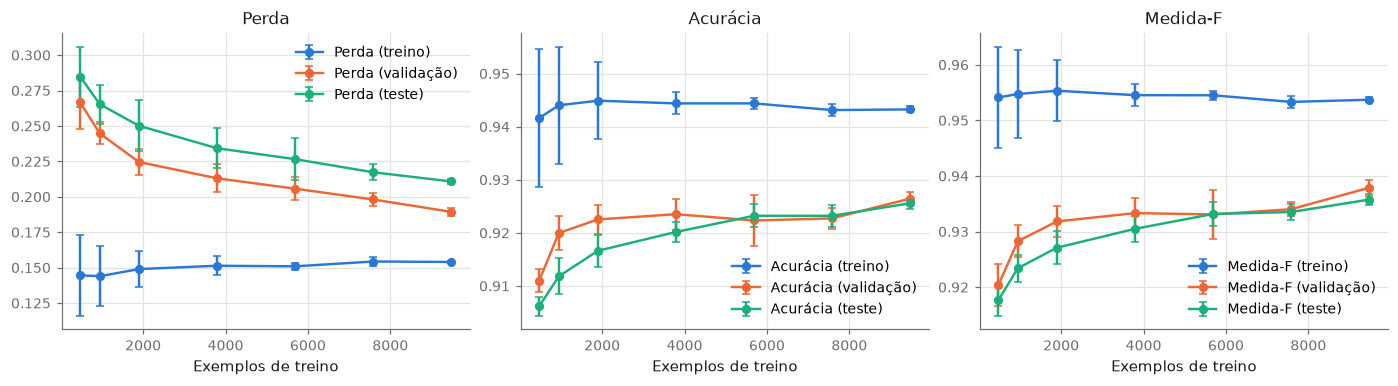

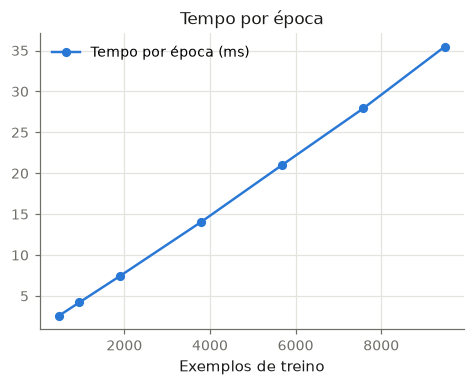

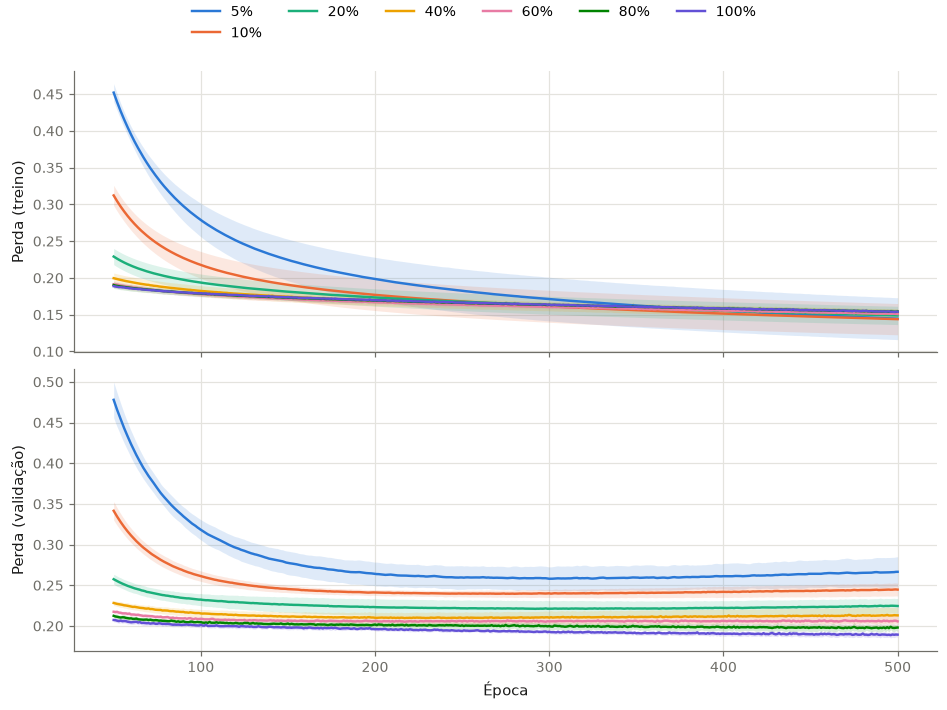

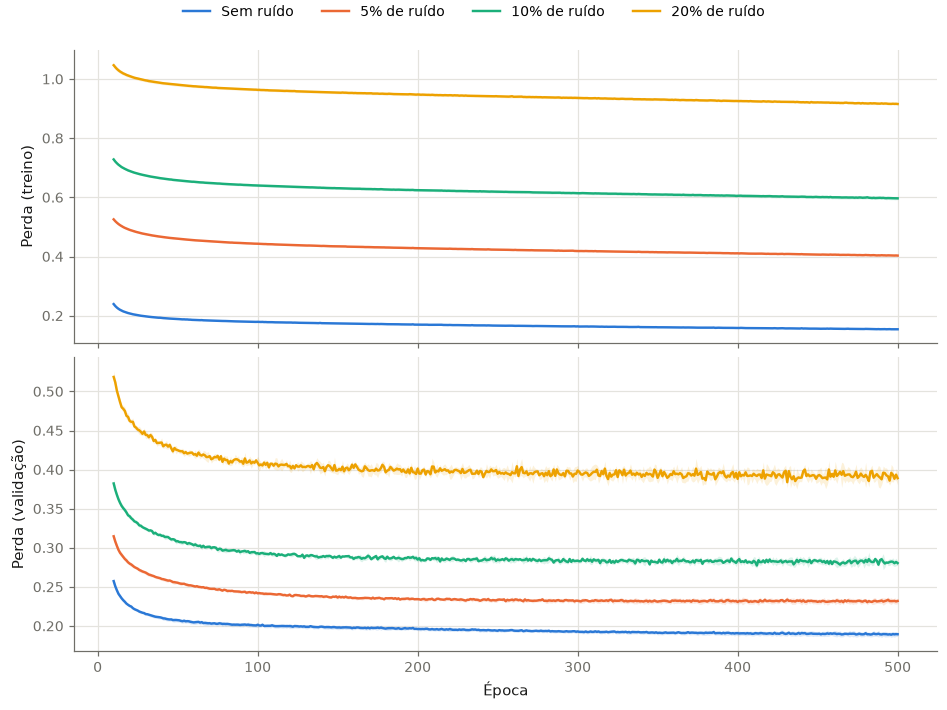

In [14]:
save_figure(
    plots.plot_by_size(
        q4_size_agg,
        x="n_train",
        metrics_by_panel={
            "Perda": ("train_loss", "val_loss", "test_loss"),
            "Acurácia": ("train_accuracy", "val_accuracy", "test_accuracy"),
            "Medida-F": ("train_f1", "val_f1", "test_f1"),
        },
        x_label="Exemplos de treino",
    ),
    "q4_generalizacao",
)
save_figure(
    plots.plot_by_size(
        q4_size_agg, x="n_train", metrics_by_panel={"Tempo por época": ("ms_per_epoch",)},
        x_label="Exemplos de treino",
    ),
    "q4_tempo",
)
save_figure(
    plots.plot_curves(
        q4_size.histories, hue="label", hue_order=["5%", "10%", "20%", "40%", "60%", "80%", "100%"],
        metrics=("train_loss", "val_loss"), min_epoch=50,
    ),
    "q4_curvas_fracoes",
)

noise_history = pd.concat(
    [q4_size.histories[q4_size.histories["label"] == "100%"].assign(label="Sem ruído"), q4_noise.histories]
)
save_figure(
    plots.plot_curves(
        noise_history, hue="label",
        hue_order=["Sem ruído", "5% de ruído", "10% de ruído", "20% de ruído"],
        metrics=("train_loss", "val_loss"), min_epoch=10,
    ),
    "q4_curvas_ruido",
);

**Leitura.** Do menor ao maior treino, a Medida-F de teste vai de 0,918 a 0,936 e a diferença entre perdas diminui. Depois
de 40% dos dados o ganho é pequeno (0,005 na Medida-F de teste), embora a perda de validação continue caindo. O tempo
por época é linear no número de exemplos. Rótulos errados afetam mais a perda do que a Medida-F: com 20% de ruído
a perda de validação dobra (0,19 para 0,39), mas a Medida-F de teste cai só de 0,936 para 0,931. A amostragem aleatória
empata em média com a estratificada, mas com 5% dos dados tem dispersão quase três vezes maior.

## Questão 5: quantidade, qualidade e sensibilidade dos atributos

**Critérios.**

- **Relevância:** importância por permutação na validação, com média entre três redes.
- **Redundância:** |r| > 0,95 no treino. De cada grupo correlacionado fica o atributo mais importante.
- **Ruído:** colunas gaussianas artificiais adicionadas à entrada.

**Regra de escolha (definida antes de rodar).** Entre os subconjuntos nomeados, o menor cuja Medida-F na
validação fique a até um desvio da melhor. O teste é apenas reportado.

In [15]:
ranking = rank_features(best_config, splits, THREE_SEEDS)
ORDERED = tuple(ranking["feature"])
NON_REDUNDANT = drop_redundant(splits.X_train, ORDERED)

show(ranking.rename(columns={"feature": "Atributo", "importance": "Queda de F1", "importance_std": "dp"}), "q5_importancia")
print("Sem redundantes:", NON_REDUNDANT)

SUBSETS = {
    "Todos": tuple(X.columns),
    "Top 12": ORDERED[:12],
    "Top 8": ORDERED[:8],
    "Top 4": ORDERED[:4],
    f"Sem redundantes ({len(NON_REDUNDANT)})": NON_REDUNDANT,
    "Só tamanho": SIZE_FEATURES,
    "Só forma": SHAPE_FEATURES,
}

trials = [Trial(name, best_config, seed, features=features)
          for name, features in SUBSETS.items() for seed in THREE_SEEDS]
trials += [Trial("Todos + 5 de ruído", best_config, seed, noise_features=5) for seed in THREE_SEEDS]
trials += [
    Trial("8 aleatórios", best_config, seed,
          features=tuple(np.random.default_rng(seed).choice(X.columns, size=8, replace=False)))
    for seed in FIVE_SEEDS
]
q5 = run_trials(trials, splits, monitor=("val", "test"))
q5_agg = aggregate(q5.summary)
q5_timing = measure_epoch_time(
    [trial for trial in trials if trial.seed == 0 and trial.label != "8 aleatórios"], splits
)
q5_agg = q5_agg.merge(q5_timing[["label", "ms_per_epoch"]], on="label", how="left")


def q5_view(table):
    return table[["label", "n_features", "train_loss_mean", "val_loss_mean", "val_accuracy_mean", "val_f1_mean",
                  "val_f1_std", "test_f1_mean", "epochs_to_aux_mean", "ms_per_epoch"]].rename(
        columns={
            "label": "Conjunto",
            "n_features": "N",
            "train_loss_mean": "Perda treino",
            "val_loss_mean": "Perda val.",
            "val_accuracy_mean": "Acur. val.",
            "val_f1_mean": "F1 val.",
            "val_f1_std": "dp F1",
            "test_f1_mean": "F1 teste",
            "epochs_to_aux_mean": "Épocas até 0,20",
            "ms_per_epoch": "ms/época",
        }
    )


show(q5_view(q5_agg), "q5_subconjuntos")

named = q5_agg[q5_agg["label"].isin(SUBSETS)]
best_named = named.loc[named["val_f1_mean"].idxmax()]
tolerable = named[named["val_f1_mean"] >= best_named["val_f1_mean"] - best_named["val_f1_std"]]
chosen_subset = tolerable.sort_values(["n_features", "val_f1_mean"], ascending=[True, False]).iloc[0]
BEST_FEATURES = SUBSETS[chosen_subset["label"]]
print(f"Subconjunto escolhido: {chosen_subset['label']} ({len(BEST_FEATURES)} atributos)")
print(BEST_FEATURES)

Atributo,Queda de F1,dp
roundness,0.1139,0.0032
ConvexArea,0.1028,0.0347
ShapeFactor4,0.1022,0.0030
ShapeFactor1,0.0915,0.0251
ShapeFactor2,0.0746,0.0339
Area,0.0712,0.0166
Eccentricity,0.0526,0.0046
Compactness,0.0344,0.0091
MinorAxisLength,0.0338,0.0054
EquivDiameter,0.0255,0.0106


Sem redundantes: ('roundness', 'ConvexArea', 'ShapeFactor4', 'ShapeFactor1', 'ShapeFactor2', 'Eccentricity', 'Solidity', 'AspectRation', 'MajorAxisLength', 'Extent')


Conjunto,N,Perda treino,Perda val.,Acur. val.,F1 val.,dp F1,F1 teste,"Épocas até 0,20",ms/época
Todos,16,0.1539,0.1882,0.9265,0.9380,0.0006,0.9353,27.3333,35.6292
Top 12,12,0.1628,0.1925,0.9240,0.9349,0.0003,0.9328,31.0000,35.0410
Top 8,8,0.1730,0.1943,0.9214,0.9325,0.0017,0.9312,43.6667,34.5245
Top 4,4,0.1843,0.1950,0.9214,0.9318,0.0021,0.9274,112.0000,33.7152
Sem redundantes (10),10,0.1554,0.1855,0.9250,0.9365,0.0004,0.9345,26.3333,34.9778
Só tamanho,6,0.2245,0.2499,0.9111,0.9197,0.0011,0.9210,nan,32.6806
Só forma,10,0.1536,0.1871,0.9267,0.9384,0.0018,0.9362,36.6667,34.7463
Todos + 5 de ruído,21,0.1258,0.2179,0.9209,0.9325,0.0014,0.9288,30.0000,36.6893
8 aleatórios,8,0.2001,0.2258,0.9138,0.9223,0.0117,0.9243,238.2500,nan


Subconjunto escolhido: Só forma (10 atributos)
('AspectRation', 'Eccentricity', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4')


In [16]:
q5_loo = run_trials(
    [Trial(f"Sem {feature}", best_config, seed, features=tuple(c for c in X.columns if c != feature))
     for feature in X.columns for seed in THREE_SEEDS],
    splits,
    monitor=("val", "test"),
)
q5_loo_agg = aggregate(q5_loo.summary)
full_f1 = q5_agg.loc[q5_agg["label"] == "Todos", "val_f1_mean"].iloc[0]
q5_loo_agg["delta"] = q5_loo_agg["val_f1_mean"] - full_f1
q5_loo_table = q5_loo_agg.sort_values("delta")
show(
    q5_loo_table[["label", "val_f1_mean", "val_f1_std", "delta", "test_f1_mean"]].rename(
        columns={"label": "Remoção", "val_f1_mean": "F1 val.", "val_f1_std": "dp", "delta": "Variação", "test_f1_mean": "F1 teste"}
    ),
    "q5_remocao",
)

Remoção,F1 val.,dp,Variação,F1 teste
Sem ShapeFactor4,0.9305,0.0011,-0.0075,0.9274
Sem Extent,0.9343,0.0012,-0.0037,0.9329
Sem Solidity,0.9354,0.0010,-0.0026,0.9340
Sem ShapeFactor3,0.9364,0.0026,-0.0016,0.9346
Sem Perimeter,0.9373,0.0007,-0.0008,0.9363
Sem Eccentricity,0.9376,0.0009,-0.0004,0.9363
Sem ShapeFactor1,0.9376,0.0010,-0.0004,0.9338
Sem roundness,0.9379,0.0017,-0.0001,0.9350
Sem AspectRation,0.9380,0.0005,0.0000,0.9349
Sem MinorAxisLength,0.9381,0.0011,0.0001,0.9349


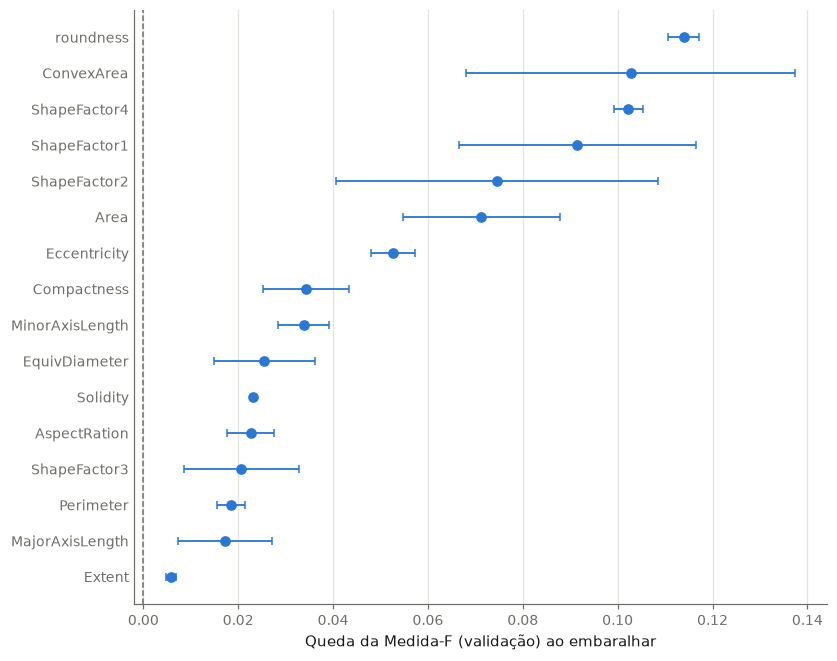

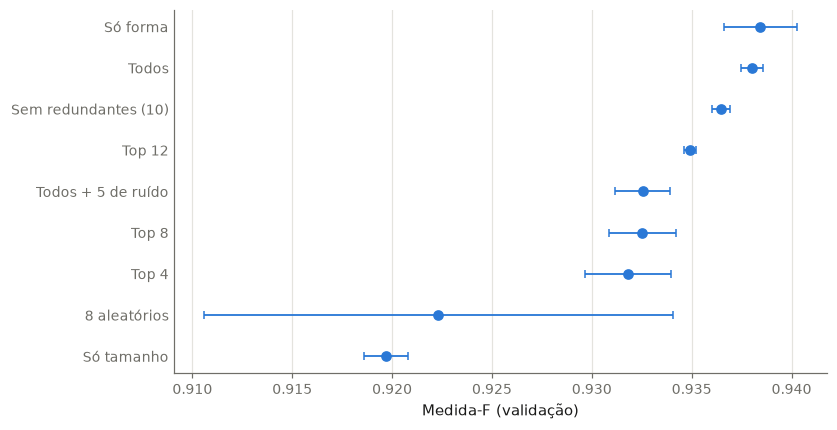

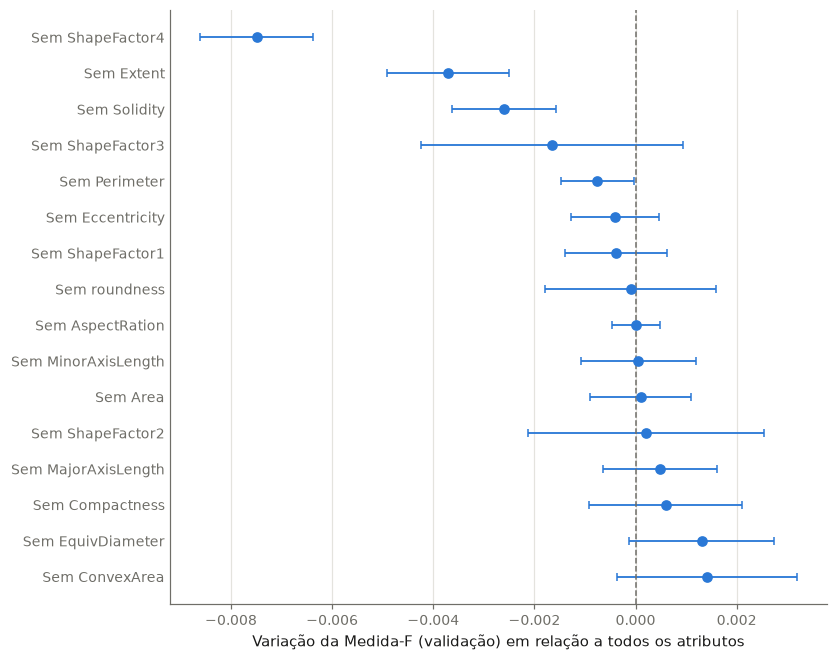

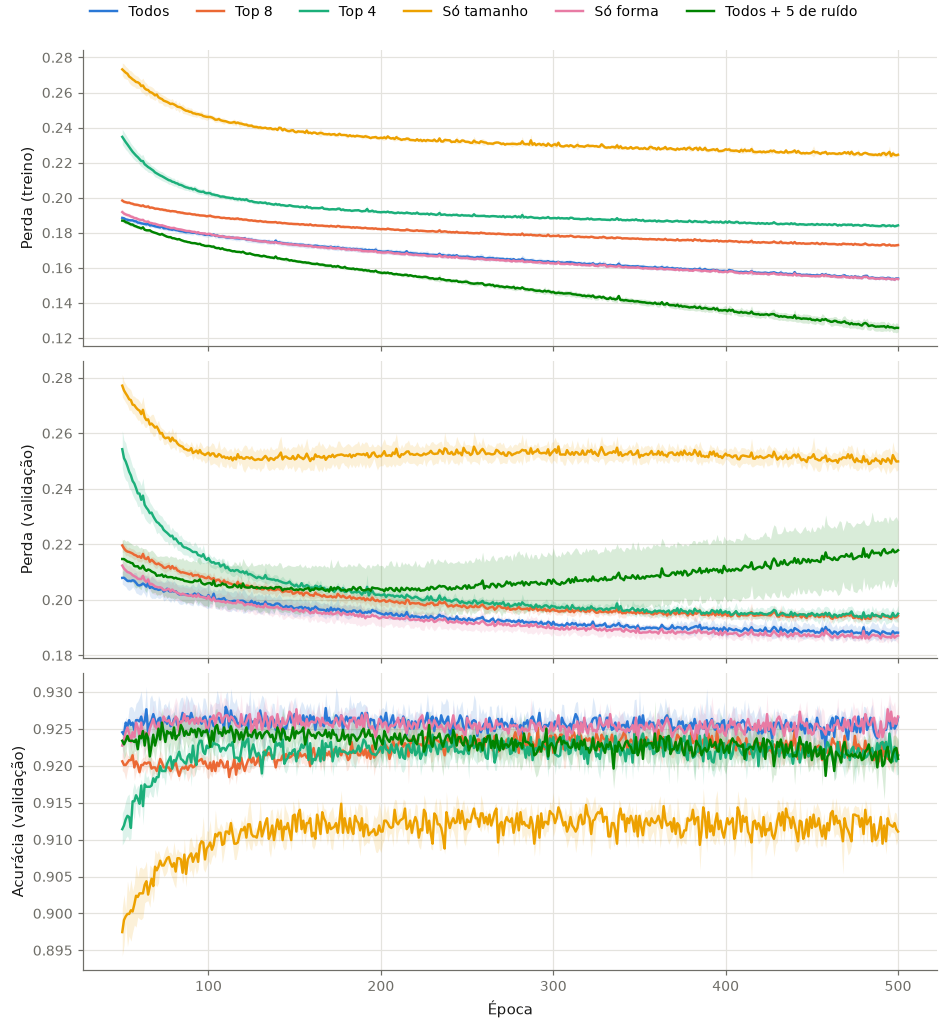

In [17]:
save_figure(
    plots.plot_dots(ranking, "feature", "importance", "importance_std", x_label="Queda da Medida-F (validação) ao embaralhar", reference=0),
    "q5_importancia",
)
save_figure(
    plots.plot_dots(q5_agg.sort_values("val_f1_mean", ascending=False), "label", "val_f1_mean", "val_f1_std", x_label="Medida-F (validação)"),
    "q5_subconjuntos",
)
save_figure(
    plots.plot_dots(q5_loo_table, "label", "delta", "val_f1_std", x_label="Variação da Medida-F (validação) em relação a todos os atributos", reference=0),
    "q5_remocao",
)
curve_labels = ["Todos", "Top 8", "Top 4", "Só tamanho", "Só forma", "Todos + 5 de ruído"]
save_figure(
    plots.plot_curves(q5.histories, hue="label", hue_order=curve_labels, metrics=("train_loss", "val_loss", "val_accuracy"), min_epoch=50),
    "q5_curvas",
);

**Leitura.** O subconjunto escolhido foi "Só forma" (10 atributos), com Medida-F de validação equivalente à de todos os atributos.
Seis atributos de tamanho sozinhos caem para 0,920, e as colunas de ruído pioram a generalização: a perda de treino cai,
a de validação sobe. Permutação e remoção discordam: `ConvexArea` parece muito importante quando embaralhado, mas removê-lo
não faz falta, porque outros atributos carregam a mesma informação. `ShapeFactor4` é o único cuja remoção custa claramente.

## Questão 6: validação inicial no conjunto de teste

**Ajustes, todos decididos na validação.**

1. **Atributos:** o subconjunto escolhido na Q5.
2. **Regularização:** `alpha` em {10⁻⁴, 10⁻³, 10⁻²} para cada uma das quatro topologias.
3. **Épocas:** limite igual à época média de menor perda de validação, para reduzir o overfitting.

Com a configuração ajustada, cada rede é treinada com cinco seeds e **avaliada no teste**. A vencedora é a
de maior média − desvio da Medida-F no teste, conforme pede o enunciado.

In [18]:
ALPHAS = (1e-4, 1e-3, 1e-2)


def topology_label(layers):
    return "×".join(map(str, layers))


q6_tuning = run_trials(
    [Trial(f"{topology_label(layers)} α={alpha:g}", topology_config(layers, alpha=alpha), seed, features=BEST_FEATURES)
     for layers in TOP_TOPOLOGIES for alpha in ALPHAS for seed in THREE_SEEDS],
    splits,
    monitor=("val",),
)
q6_tuning_agg = aggregate(q6_tuning.summary)
show(
    q6_tuning_agg[["hidden_layers", "alpha", "train_loss_mean", "val_loss_mean", "val_loss_min_mean",
                   "val_loss_min_epoch_mean", "val_f1_mean"]].rename(
        columns={
            "hidden_layers": "Topologia",
            "alpha": "alpha",
            "train_loss_mean": "Perda treino",
            "val_loss_mean": "Perda val.",
            "val_loss_min_mean": "Perda val. mín.",
            "val_loss_min_epoch_mean": "Época val. mín.",
            "val_f1_mean": "F1 val.",
        }
    ),
    "q6_ajustes",
)

tuned = q6_tuning_agg.loc[q6_tuning_agg.groupby("hidden_layers", sort=False)["val_loss_min_mean"].idxmin()]
FINALISTS = {
    row["hidden_layers"]: topology_config(
        tuple(int(n) for n in row["hidden_layers"].split("×")),
        alpha=float(row["alpha"]),
        max_epochs=int(round(row["val_loss_min_epoch_mean"])),
    )
    for _, row in tuned.iterrows()
}
for name, config in FINALISTS.items():
    print(name, "| alpha =", config.alpha, "| épocas =", config.max_epochs)

Topologia,alpha,Perda treino,Perda val.,Perda val. mín.,Época val. mín.,F1 val.
80×80,0.0001,0.1536,0.1871,0.1857,481.0000,0.9384
80×80,0.0010,0.1537,0.1872,0.1857,481.0000,0.9383
80×80,0.0100,0.1545,0.1875,0.1860,485.6667,0.9382
90×90,0.0001,0.1552,0.1892,0.1874,467.6667,0.9378
90×90,0.0010,0.1553,0.1893,0.1875,467.6667,0.9382
90×90,0.0100,0.1560,0.1888,0.1870,480.3333,0.9379
80×80×80,0.0001,0.1422,0.1930,0.1853,331.6667,0.9379
80×80×80,0.0010,0.1424,0.1934,0.1851,323.6667,0.9376
80×80×80,0.0100,0.1434,0.1916,0.1847,342.3333,0.9385
60×60×60,0.0001,0.1417,0.1976,0.1900,268.6667,0.9375


80×80 | alpha = 0.0001 | épocas = 481
90×90 | alpha = 0.01 | épocas = 480
80×80×80 | alpha = 0.01 | épocas = 342
60×60×60 | alpha = 0.0001 | épocas = 269


In [19]:
q6 = run_trials(
    [Trial(name, config, seed, features=BEST_FEATURES) for name, config in FINALISTS.items() for seed in FIVE_SEEDS],
    splits,
    monitor=("test",),
)
q6_agg = aggregate(q6.summary)
q6_agg["epochs_limit"] = [FINALISTS[name].max_epochs for name in q6_agg["label"]]

show(
    q6_agg[["label", "alpha", "epochs_limit", "train_loss_mean", "test_loss_mean", "train_accuracy_mean",
            "test_accuracy_mean", "train_f1_mean", "test_f1_mean", "test_f1_std"]].rename(
        columns={
            "label": "Topologia",
            "alpha": "alpha",
            "epochs_limit": "Épocas",
            "train_loss_mean": "Perda treino",
            "test_loss_mean": "Perda teste",
            "train_accuracy_mean": "Acur. treino",
            "test_accuracy_mean": "Acur. teste",
            "train_f1_mean": "F1 treino",
            "test_f1_mean": "F1 teste",
            "test_f1_std": "dp F1",
        }
    ),
    "q6_finalistas",
)

WINNER = top_k(q6_agg, k=1, metric="test_f1").iloc[0]["label"]
WINNER_CONFIG = FINALISTS[WINNER]
print("Vencedora:", WINNER, WINNER_CONFIG)

Topologia,alpha,Épocas,Perda treino,Perda teste,Acur. treino,Acur. teste,F1 treino,F1 teste,dp F1
80×80,0.0001,481,0.1542,0.2139,0.9434,0.9249,0.9540,0.9359,0.0011
90×90,0.0100,480,0.1560,0.2114,0.9423,0.9254,0.9530,0.9361,0.0022
80×80×80,0.0100,342,0.1506,0.2184,0.9447,0.9238,0.9549,0.9345,0.0010
60×60×60,0.0001,269,0.1570,0.2137,0.9425,0.9242,0.9527,0.9353,0.0020


Vencedora: 80×80 MLPConfig(hidden_layers=(80, 80), activation='relu', learning_rate=0.01, momentum=0.7, alpha=0.0001, batch_size=200, max_epochs=481, target_loss=0.001)


Classe,Precisão,Revocação,Medida-F,Exemplos
BARBUNYA,0.9235,0.9141,0.9188,198
BOMBAY,1.0000,1.0000,1.0000,78
CALI,0.9216,0.9592,0.9400,245
DERMASON,0.9324,0.9079,0.9200,532
HOROZ,0.9701,0.9319,0.9506,279
SEKER,0.9535,0.9441,0.9488,304
SIRA,0.8486,0.8914,0.8695,396
macro avg,0.9357,0.9355,0.9354,2032


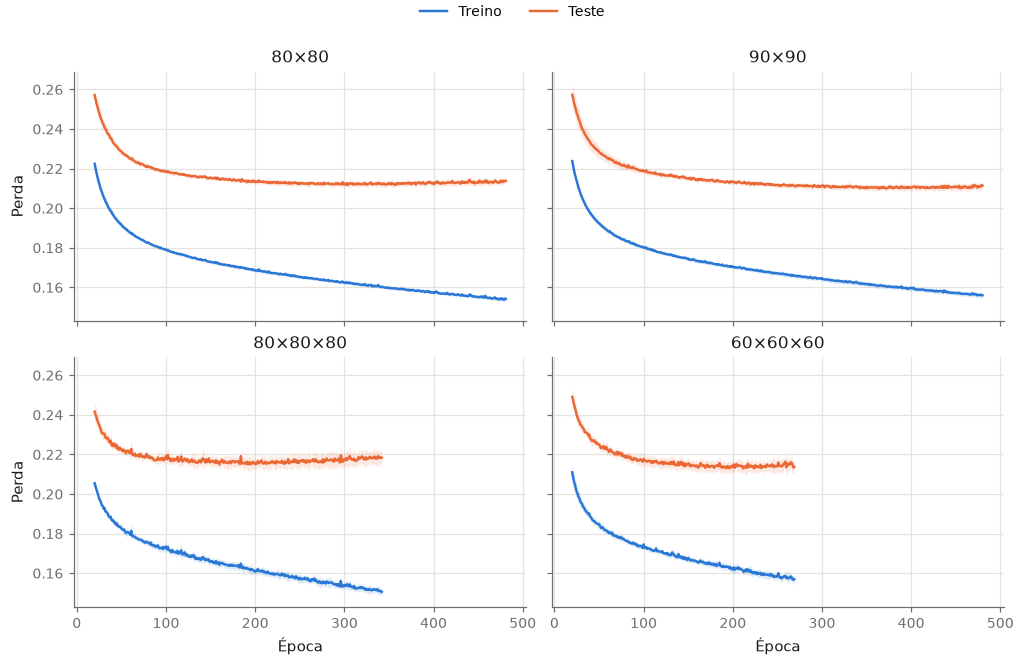

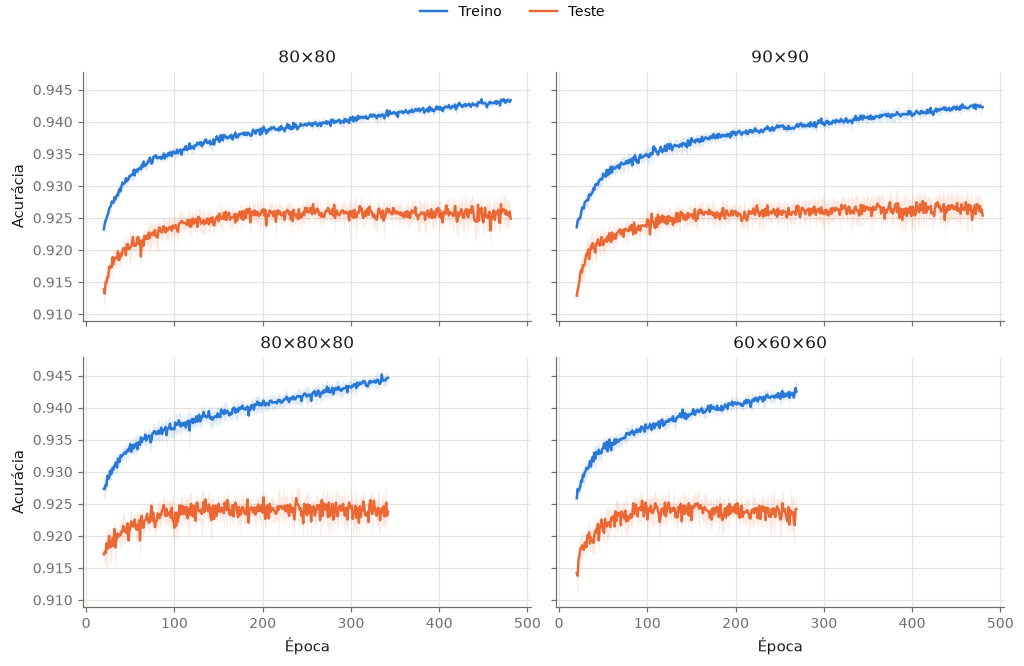

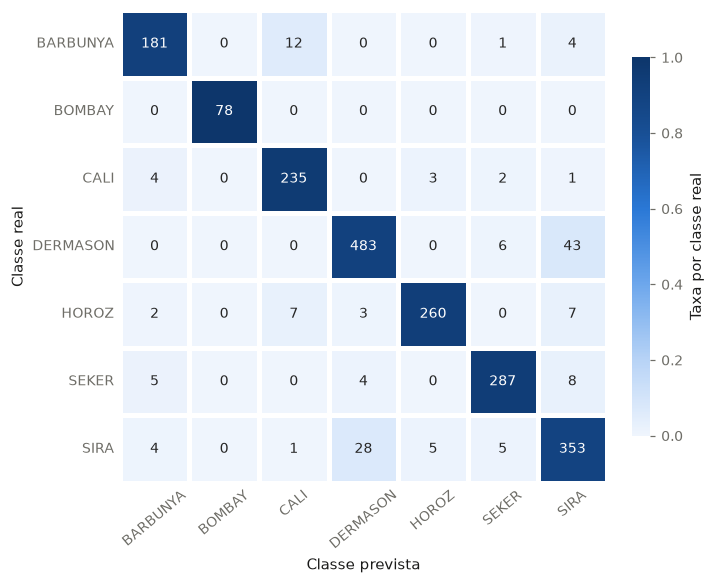

In [20]:
winner_runs = q6.summary[q6.summary["label"] == WINNER].sort_values("test_f1")
median_seed = int(winner_runs.iloc[len(winner_runs) // 2]["seed"])
winner_predictions = q6.predictions[WINNER, median_seed, "test"]

report = pd.DataFrame(classification_report(splits.y_test, winner_predictions, output_dict=True, zero_division=0)).T
report = report.loc[CLASSES + ["macro avg"]].reset_index().rename(
    columns={"index": "Classe", "precision": "Precisão", "recall": "Revocação", "f1-score": "Medida-F", "support": "Exemplos"}
)
report["Exemplos"] = report["Exemplos"].astype(int)
show(report, "q6_por_classe")

labels = list(FINALISTS)
save_figure(plots.plot_train_vs_eval(q6.histories, labels, eval_name="test", metric="loss", min_epoch=20), "q6_curvas_perda")
save_figure(plots.plot_train_vs_eval(q6.histories, labels, eval_name="test", metric="accuracy", min_epoch=20), "q6_curvas_acuracia")
save_figure(plots.plot_confusion(splits.y_test, winner_predictions, CLASSES), "q6_confusao");

**Leitura.** A vencedora é 80×80 (α = 10⁻⁴, 481 épocas), com Medida-F de 0,936 no teste. As quatro redes ficam a até 0,0016
umas das outras, menos do que o desvio entre seeds de algumas delas, e `alpha` quase não muda a validação. A diferença
entre treino e teste é estável ao longo das épocas. Bombay é sempre acertada; o erro se concentra entre Sira e Dermason.

## Questão 7: validação cruzada k-fold

**Configuração.** Rede vencedora da Q6 com `StratifiedKFold` e k = 10 sobre a base inteira. Com k = 10,
cada teste tem cerca de 1.354 exemplos (cerca de 52 da menor classe, Bombay) e cada treino usa 90% dos dados.
O z-score é reajustado em cada partição, e a seed dos pesos é fixa para isolar o efeito da partição.

A regressão logística, nas mesmas partições, indica quanto a MLP acrescenta em relação a um modelo linear.

In [21]:
K = 10
X_final = X[list(BEST_FEATURES)]
q7 = cross_validate_mlp(WINNER_CONFIG, X_final, y, k=K)

METRICS = {"test_loss": "Perda", "test_accuracy": "Acurácia", "test_f1": "Medida-F",
           "test_precision": "Precisão", "test_recall": "Revocação"}
q7_folds = q7.summary[["label", *METRICS, "train_loss"]].rename(
    columns={"label": "Partição", **METRICS, "train_loss": "Perda treino"}
)
show(q7_folds, "q7_particoes")

q7_stats = (
    q7.summary[list(METRICS)].rename(columns=METRICS).agg(["mean", "var", "std", "min", "max"]).T.reset_index()
    .rename(columns={"index": "Métrica", "mean": "Média", "var": "Variância", "std": "Desvio", "min": "Mínimo", "max": "Máximo"})
)
show(q7_stats, "q7_estatisticas", digits=5)

Partição,Perda,Acurácia,Medida-F,Precisão,Revocação,Perda treino
fold 1,0.2417,0.9151,0.9291,0.9312,0.9275,0.1561
fold 2,0.2039,0.9299,0.9437,0.9459,0.9420,0.1575
fold 3,0.1740,0.9402,0.9500,0.9504,0.9497,0.1613
fold 4,0.1895,0.9291,0.9385,0.9422,0.9352,0.1594
fold 5,0.1893,0.9247,0.9348,0.9348,0.9351,0.1599
fold 6,0.1447,0.9476,0.9572,0.9576,0.9568,0.1630
fold 7,0.1680,0.9417,0.9496,0.9517,0.9476,0.1610
fold 8,0.1652,0.9431,0.9512,0.9517,0.9508,0.1612
fold 9,0.1883,0.9254,0.9392,0.9409,0.9379,0.1604
fold 10,0.1805,0.9321,0.9422,0.9417,0.9430,0.1604


Métrica,Média,Variância,Desvio,Mínimo,Máximo
Perda,0.18452,0.00067,0.02597,0.14468,0.24172
Acurácia,0.93288,0.00010,0.01008,0.91513,0.94756
Medida-F,0.94355,0.00007,0.00853,0.92908,0.95716
Precisão,0.94482,0.00007,0.00823,0.93120,0.95763
Revocação,0.94258,0.00008,0.00886,0.92752,0.95683


In [22]:
logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
folds = StratifiedKFold(n_splits=K, shuffle=True, random_state=42)
baseline_cv = cross_validate(
    logistic, X_final, y, cv=folds, n_jobs=-1,
    scoring={"loss": "neg_log_loss", "accuracy": "accuracy", "f1": "f1_macro"},
)
paired_gain = q7.summary["test_f1"].to_numpy() - baseline_cv["test_f1"]
comparison = pd.DataFrame(
    {
        "Modelo": ["MLP", "Regressão logística"],
        "Perda": [q7.summary["test_loss"].mean(), -baseline_cv["test_loss"].mean()],
        "Acurácia": [q7.summary["test_accuracy"].mean(), baseline_cv["test_accuracy"].mean()],
        "Medida-F": [q7.summary["test_f1"].mean(), baseline_cv["test_f1"].mean()],
        "dp Medida-F": [q7.summary["test_f1"].std(), baseline_cv["test_f1"].std(ddof=1)],
    }
)
show(comparison, "q7_baseline")
print(f"Ganho pareado de F1 da MLP: {paired_gain.mean():+.4f} ± {paired_gain.std(ddof=1):.4f}; "
      f"MLP melhor em {(paired_gain > 0).sum()} de {K} partições")

Modelo,Perda,Acurácia,Medida-F,dp Medida-F
MLP,0.1845,0.9329,0.9436,0.0085
Regressão logística,0.2190,0.9246,0.9365,0.0080


Ganho pareado de F1 da MLP: +0.0070 ± 0.0050; MLP melhor em 8 de 10 partições


Pior, mediana e melhor partição: ['fold 1', 'fold 2', 'fold 6']


Classe,Precisão,Revocação,Medida-F,Exemplos
BARBUNYA,0.9433,0.9312,0.9372,1322
BOMBAY,0.9981,1.0000,0.9990,522
CALI,0.9421,0.9485,0.9453,1630
DERMASON,0.9169,0.9363,0.9265,3546
HOROZ,0.9645,0.9500,0.9572,1860
SEKER,0.9594,0.9551,0.9572,2027
SIRA,0.8882,0.8771,0.8826,2636


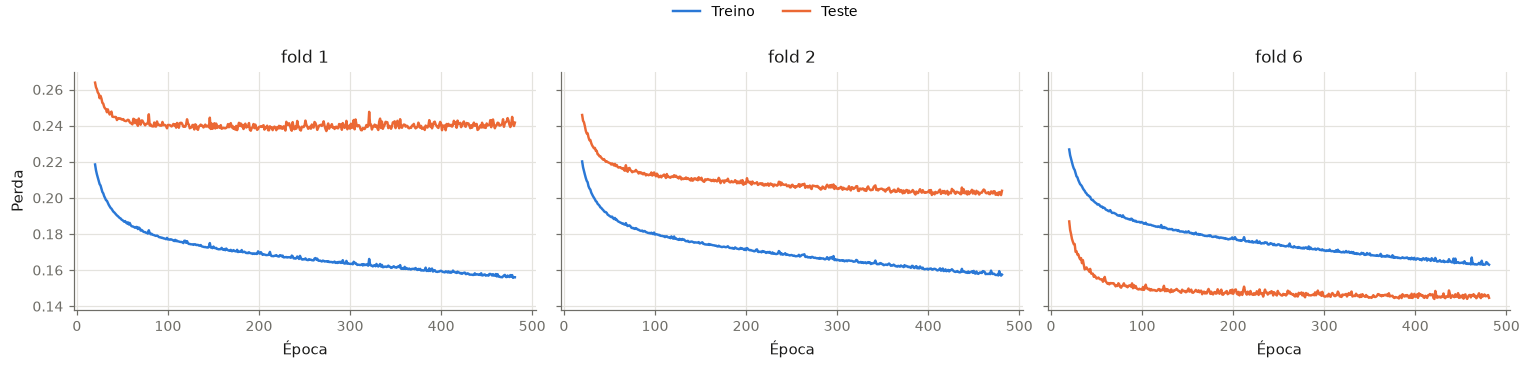

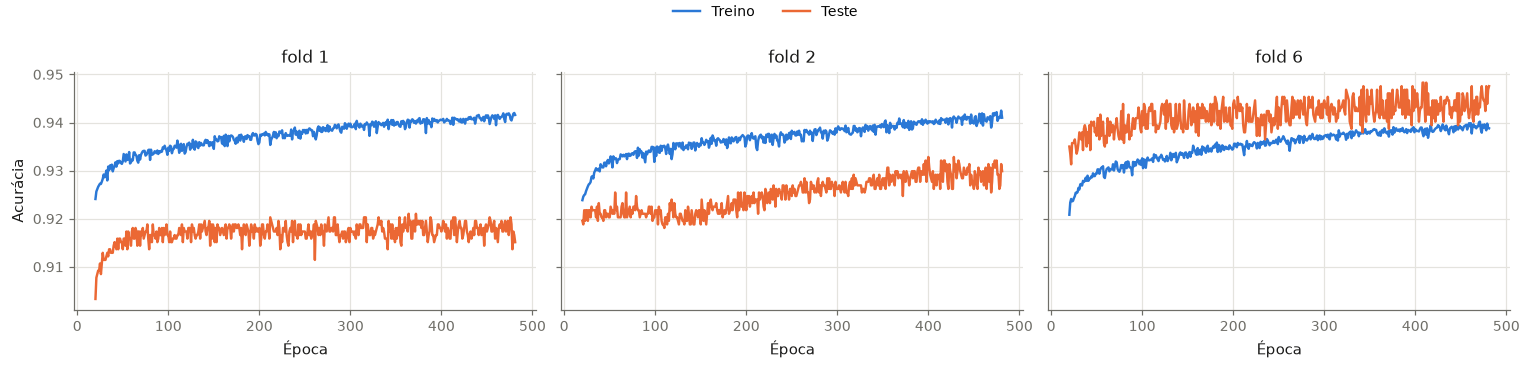

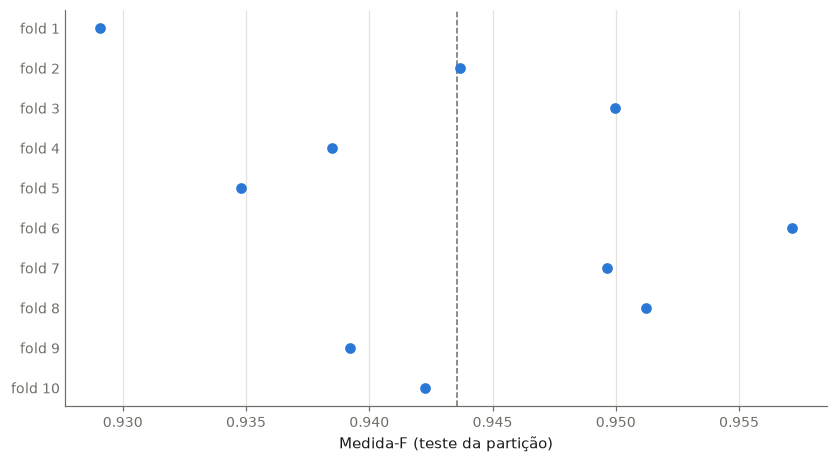

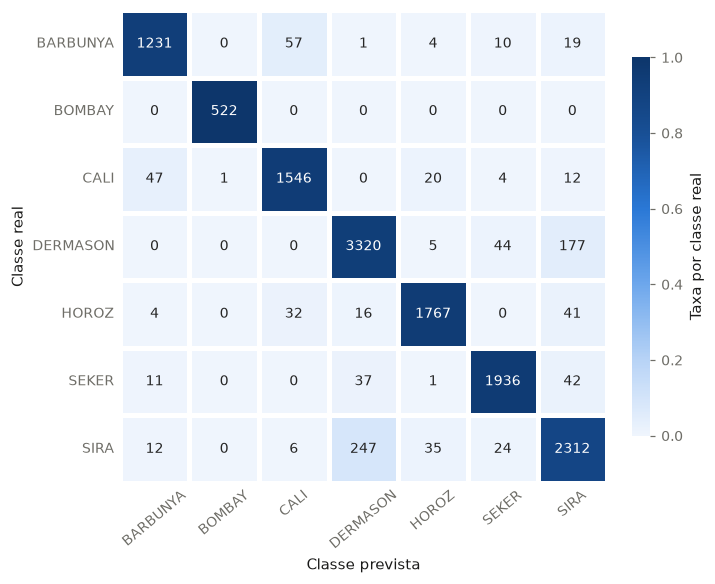

In [23]:
by_f1 = q7.summary.sort_values("test_f1")["label"].tolist()
representative = [by_f1[0], by_f1[len(by_f1) // 2], by_f1[-1]]
print("Pior, mediana e melhor partição:", representative)

save_figure(plots.plot_train_vs_eval(q7.histories, representative, eval_name="test", metric="loss", ncols=3, min_epoch=20), "q7_curvas_perda")
save_figure(plots.plot_train_vs_eval(q7.histories, representative, eval_name="test", metric="accuracy", ncols=3, min_epoch=20), "q7_curvas_acuracia")
save_figure(
    plots.plot_dots(q7.summary, "label", "test_f1", x_label="Medida-F (teste da partição)", reference=q7.summary["test_f1"].mean()),
    "q7_particoes",
)

fold_splits = list(folds.split(X_final, y))
y_true_all = np.concatenate([y.iloc[test].to_numpy() for _, test in fold_splits])
y_pred_all = np.concatenate([q7.predictions[f"fold {i}", 42, "test"] for i in range(1, K + 1)])
save_figure(plots.plot_confusion(y_true_all, y_pred_all, CLASSES), "q7_confusao")

report_all = pd.DataFrame(classification_report(y_true_all, y_pred_all, output_dict=True, zero_division=0)).T
report_all = report_all.loc[CLASSES].reset_index().rename(
    columns={"index": "Classe", "precision": "Precisão", "recall": "Revocação", "f1-score": "Medida-F", "support": "Exemplos"}
)
report_all["Exemplos"] = report_all["Exemplos"].astype(int)
show(report_all, "q7_por_classe")

**Leitura.** Medida-F de 0,9436 ± 0,0085 nas dez partições, entre 0,9291 e 0,9572. Essa dispersão é maior que toda a faixa
de resultados da Q3 (0,0062): a partição dos dados pesa mais do que a escolha da topologia. A regressão logística chega a
0,9365, e a MLP ganha em 8 de 10 partições, com ganho médio de 0,0070 ± 0,0050.